# Autenticación de billetes: regresión logística frente a Random Forest

Comparación de dos algoritmos de aprendizaje supervisado para distinguir billetes genuinos de falsificados con el conjunto *Banknote Authentication* (UCI Machine Learning Repository).

| Sección | Contenido |
|---|---|
| 1 | Datos, análisis exploratorio, preparación sin fuga de información y regresión logística como línea base |
| 2 | Random Forest con validación cruzada anidada, importancia de variables y reglas de decisión |
| 3 | Comparación de los modelos: métricas, curvas ROC, prueba estadística, errores y efecto de los registros duplicados |

Ejecución: El notebook se ejecuta de principio a fin (*Restart & Run All*) desde la carpeta `notebooks/`, con el dataset en `../data/`. Las figuras se guardan en `../report/plots/` y las tablas de resultados en `../results/`. La búsqueda de hiperparámetros de la sección 2 es la parte más lenta (unos minutos).

# 1. Datos y modelo lineal base

## 1.0 Alcance, problema y objetivo

Esta sección cubre:

- análisis exploratorio de datos (EDA);
- preparación reproducible y control de *data leakage*;
- regresión logística como modelo lineal base.

No se incluyen aquí Random Forest, ajuste de hiperparámetros del modelo no lineal, curvas ROC comparativas ni pruebas estadísticas entre modelos, porque se desarrollan en las secciones 2 y 3.

### Contexto

El conjunto **Banknote Authentication** contiene observaciones de billetes descritos por cuatro variables continuas obtenidas a partir de imágenes transformadas mediante wavelets. La etiqueta indica si el billete es genuino (`0`) o falso (`1`). El objetivo de esta parte es construir una línea base sólida y explicable que permita saber qué tan bien puede separar las clases un modelo lineal.

![Billete de referencia](https://upload.wikimedia.org/wikipedia/commons/1/1d/United_States_one_dollar_bill%2C_reverse.jpg?utm_source=es.wikipedia.org&utm_campaign=index&utm_content=original)

*Imagen ilustrativa: reverso de un billete de un dólar estadounidense. Fuente: Wikimedia Commons.*

# 1.1 Pregunta de investigación y métrica principal

### Pregunta de investigación del proyecto

**¿Cuál de los dos modelos de clasificación —la regresión logística como modelo lineal base o el modelo no lineal— identifica mejor los billetes falsos, manteniendo un protocolo de evaluación estratificado, reproducible y libre de fuga de información?**

Esta es la pregunta general del proyecto completo: no busca evaluar la regresión logística de forma aislada, sino comparar dos familias de modelos bajo condiciones equivalentes. Ambos modelos deben utilizar las mismas observaciones, las mismas particiones estratificadas y la misma métrica principal, para que la diferencia observada pueda atribuirse al comportamiento de los algoritmos y no a una ventaja accidental del procedimiento experimental.

### Contribución de esta sección

Esta sección construye la referencia lineal del experimento: documenta el dataset, realiza el EDA, prepara las variables sin *data leakage* y entrena la regresión logística. La sección 2 desarrolla el modelo no lineal y la sección 3 integra la comparación de resultados, el análisis de errores y la prueba estadística.

### Métrica principal: recall de la clase falsa

La métrica principal común para comparar los dos modelos será el **recall (sensibilidad) de la clase `1`, billete falso**:

$$\text{Recall}_{falso} = \frac{TP}{TP + FN}.$$

- `TP` (*true positive*): billetes falsos correctamente detectados.
- `FN` (*false negative*): billetes falsos clasificados como genuinos.

Se selecciona esta métrica porque el falso negativo es el error operacional más riesgoso: permitir que un billete falso pase como genuino puede producir una pérdida económica directa. Un recall alto significa que el modelo detecta una mayor proporción de las falsificaciones existentes. Precision, F1 y accuracy se reportarán como métricas complementarias, ya que un sistema real también debe controlar cuántos billetes genuinos son marcados erróneamente como falsos y cuál es su rendimiento global.

> La conclusión final sobre qué modelo es preferible debe considerar el recall, la variabilidad entre pliegues, la matriz de confusión, los costos de FP/FN y la prueba estadística de la comparación. Esta celda define el criterio común; no anticipa cuál modelo ganará.

# 1.2 Preparación del entorno y criterios visuales

Se utiliza únicamente Matplotlib para las figuras. Las paletas `Blues` y `RdPu` pertenecen a Matplotlib y producen un contraste limpio: azul para la clase genuina y coral para la clase falsa. Los mismos colores se reutilizan en todos los gráficos para evitar interpretaciones visuales inconsistentes.

El `random_state=42` fija las decisiones aleatorias del experimento y hace que otra persona pueda reproducir las mismas particiones y resultados.

Cada figura se guarda automáticamente en `../report/plots` en formato PNG con 300 DPI y un nombre descriptivo, además de mostrarse en el notebook.

La matriz de dispersión se exporta como `04_matriz_dispersion_por_clase.png`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ['variance', 'skewness', 'kurtosis', 'entropy']
TARGET = 'is_fake'
RANDOM_STATE = 42
PLOTS_DIR = Path('../report/plots')
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Paleta sobria de Matplotlib: azul para genuinos y coral para falsos.
blues = plt.get_cmap('Blues')
corals = plt.get_cmap('RdPu')
COLORS = {0: blues(0.72), 1: corals(0.72)}
CLASS_LABELS = {0: 'Genuino (0)', 1: 'Falso (1)'}

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'figure.dpi': 110,
})

# 1.3 Análisis exploratorio: carga y estructura del dataset

El primer paso del EDA es comprobar que el archivo contiene la estructura que esperamos. Cada fila representa un billete y cada columna una medición o la etiqueta. Las cuatro características son numéricas continuas; la etiqueta es binaria.

- **Varianza (`variance`)**: dispersión de los valores de intensidad de la imagen transformada. Una varianza alta indica mayor variación local.
- **Asimetría (`skewness`)**: mide si la distribución de intensidades se inclina hacia un lado respecto a su centro.
- **Curtosis (`kurtosis`)**: describe el peso de las colas y qué tan apuntada o plana es la distribución.
- **Entropía (`entropy`)**: cuantifica la irregularidad o cantidad de información de la imagen transformada.

Estas variables no son píxeles individuales: son descriptores estadísticos compactos que resumen propiedades de la imagen.

In [2]:
data_path = Path('../data/data_banknote_authentication.txt')
if not data_path.exists():
    raise FileNotFoundError(f'No se encontró el dataset en: {data_path.resolve()}')

df = pd.read_csv(data_path, header=None, names=FEATURES + [TARGET])
df[TARGET] = pd.to_numeric(df[TARGET], errors='raise').astype(int)

print(f'Filas (billetes): {len(df):,}')
print(f'Columnas: {df.shape[1]} ({len(FEATURES)} características + 1 etiqueta)')
display(df.head())

Filas (billetes): 1,372
Columnas: 5 (4 características + 1 etiqueta)


,variance,skewness,kurtosis,entropy,is_fake
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


# 1.4 EDA: calidad de los datos

Antes de calcular métricas o entrenar un modelo se revisa la calidad de la tabla:

- **Valores nulos (`NaN`)**: representan información ausente. Si existieran, habría que decidir si imputarlos o eliminar observaciones; en este trabajo se detiene el flujo para no ocultar el problema.
- **Valores no finitos**: `inf` y `-inf` no son mediciones válidas y pueden romper el escalado o el optimizador.
- **Tipos de datos**: las características deben poder tratarse como números y la etiqueta debe pertenecer exactamente a `{0, 1}`.
- **Duplicados**: se reportan porque pueden hacer que algunas observaciones aparezcan repetidas. No se eliminan automáticamente: una eliminación sin justificación podría quitar información legítima.

In [3]:
expected_classes = {0, 1}
observed_classes = set(df[TARGET].unique())
if observed_classes != expected_classes:
    raise ValueError(f'Las clases esperadas son {expected_classes}, pero se encontraron {observed_classes}.')
if df[FEATURES].isna().any().any():
    raise ValueError('El dataset contiene valores ausentes en las características.')
if not np.isfinite(df[FEATURES].to_numpy()).all():
    raise ValueError('El dataset contiene valores no finitos en las características.')

quality = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'n_unicos': df.nunique(),
})
print(f'Filas duplicadas detectadas: {df.duplicated().sum()}')
display(quality)

Filas duplicadas detectadas: 24


,tipo,nulos,n_unicos
variance,float64,0,1338
skewness,float64,0,1256
kurtosis,float64,0,1270
entropy,float64,0,1156
is_fake,int64,0,2


# 1.5 EDA: estadística descriptiva e interpretación

La tabla descriptiva resume cada característica:

- **count**: número de valores disponibles. Debe coincidir con el número de filas si no hay nulos.
- **mean**: promedio; sirve como referencia del centro, aunque puede verse afectado por valores extremos.
- **std**: desviación estándar muestral; mide cuánto se dispersan los valores alrededor de la media. Una `std` grande implica una escala numérica más amplia.
- **min / max**: extremos observados; ayudan a identificar rangos y posibles valores atípicos.
- **25%, 50%, 75%**: cuartiles. El 50% es la mediana; el intervalo entre 25% y 75% contiene la mitad central de los datos.

La comparación de rangos y desviaciones es especialmente importante para la regresión logística, ya que el modelo utiliza una combinación lineal de las características.

In [4]:
descriptive_stats = df[FEATURES].describe().T
# El rango complementa a std y facilita comparar escalas entre variables.
descriptive_stats['range'] = descriptive_stats['max'] - descriptive_stats['min']
display(descriptive_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,range
variance,1372.0,0.434,2.843,-7.042,-1.773,0.496,2.821,6.825,13.867
skewness,1372.0,1.922,5.869,-13.773,-1.708,2.320,6.815,12.952,26.725
kurtosis,1372.0,1.398,4.310,-5.286,-1.575,0.617,3.179,17.927,23.214
entropy,1372.0,-1.192,2.101,-8.548,-2.413,-0.587,0.395,2.450,10.998


# 1.6 EDA: distribución de la variable objetivo

La distribución de clases indica si el problema está balanceado. Si una clase fuera muy dominante, un modelo podría obtener una exactitud engañosamente alta prediciendo casi siempre la clase mayoritaria. En este dataset las clases están relativamente equilibradas, por lo que accuracy puede ser informativa, aunque también se deben observar precision, recall y F1.

La clase `1` representa billetes falsos y la clase `0` billetes genuinos. Las etiquetas porcentuales dentro de las barras muestran la participación de cada clase en el total.

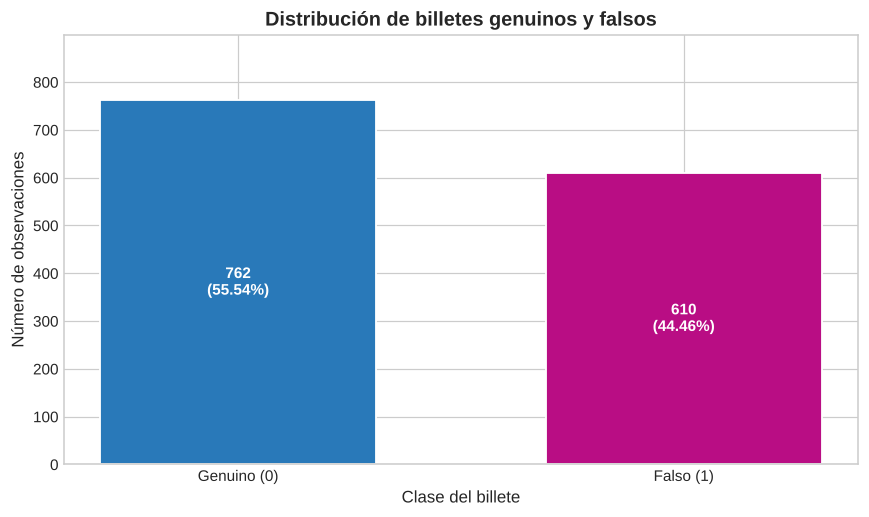

,count,percentage
is_fake,,
Genuino (0),762,55.54
Falso (1),610,44.46


In [5]:
class_counts = df[TARGET].value_counts().sort_index()
class_percentages = class_counts / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(class_counts))
bars = ax.bar(
    x,
    class_counts.to_numpy(),
    color=[COLORS[label] for label in class_counts.index],
    edgecolor='white',
    linewidth=1.2,
    width=0.62,
)
ax.set_xticks(x, [CLASS_LABELS[label] for label in class_counts.index])
ax.set_xlabel('Clase del billete')
ax.set_ylabel('Número de observaciones')
ax.set_title('Distribución de billetes genuinos y falsos')
ax.set_ylim(0, class_counts.max() * 1.18)
for bar, count, percentage in zip(bars, class_counts, class_percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 0.5,
        f'{count:,}\n({percentage:.2f}%)',
        ha='center', va='center', fontweight='bold', color='white',
    )
plt.tight_layout()
fig.savefig(PLOTS_DIR / '01_distribucion_clases.png', dpi=300, bbox_inches='tight')
plt.show()

display(pd.DataFrame({'count': class_counts, 'percentage': class_percentages.round(2)}).rename(index=CLASS_LABELS))

# 1.7 EDA: distribución de las características

Los histogramas muestran cómo se distribuye cada descriptor y si existe separación visual entre clases. Una separación clara sugiere que esa característica podría aportar información al clasificador; un gran solapamiento indica que esa variable, por sí sola, no basta para decidir.

La densidad normaliza las alturas para que las formas de las distribuciones sean comparables incluso cuando las clases tienen tamaños diferentes. Estas figuras son descriptivas: no prueban por sí solas que una variable cause la etiqueta ni sustituyen la evaluación cruzada.

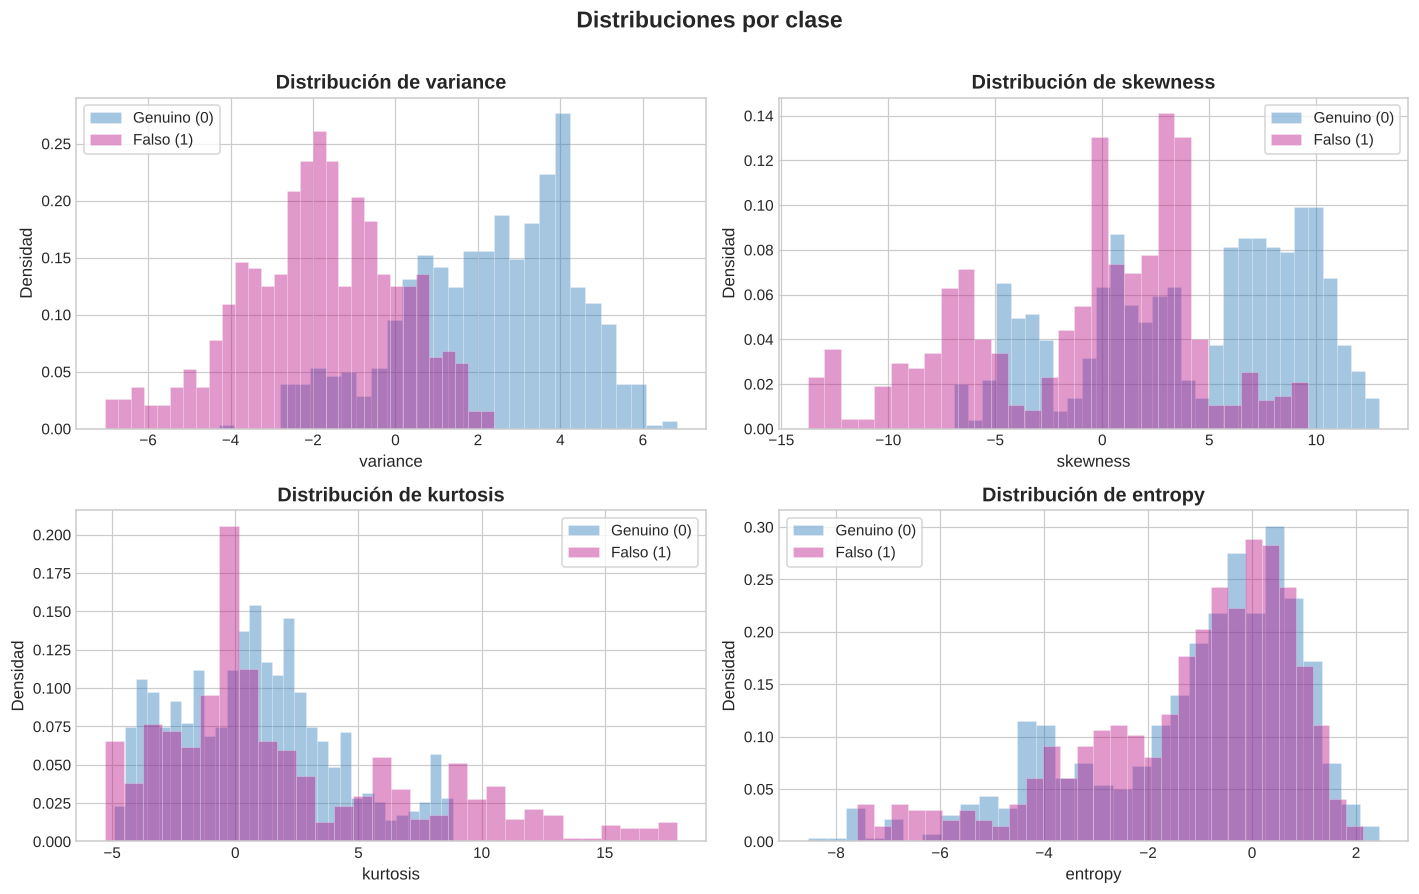

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, feature in zip(axes.flat, FEATURES):
    for label, color in COLORS.items():
        subset = df.loc[df[TARGET] == label, feature]
        ax.hist(
            subset,
            bins=30,
            density=True,
            alpha=0.42,
            color=color,
            edgecolor='white',
            linewidth=0.35,
            label=CLASS_LABELS[label],
        )
    ax.set_title(f'Distribución de {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Densidad')
    ax.legend(frameon=True)
fig.suptitle('Distribuciones por clase', y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '02_distribuciones_caracteristicas.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.8 EDA: matriz de correlación

La correlación de Pearson mide la asociación lineal entre dos variables, con valores entre `-1` y `1`:

- valores cercanos a `1`: relación lineal positiva;
- valores cercanos a `-1`: relación lineal negativa;
- valores cercanos a `0`: poca relación lineal.

La matriz ayuda a detectar predictores redundantes y a entender la estructura del espacio de características. **Correlación no significa causalidad** y una correlación baja no descarta relaciones no lineales. Para la regresión logística, correlaciones muy altas podrían dificultar la interpretación individual de los coeficientes porque varias variables aportarían información similar.

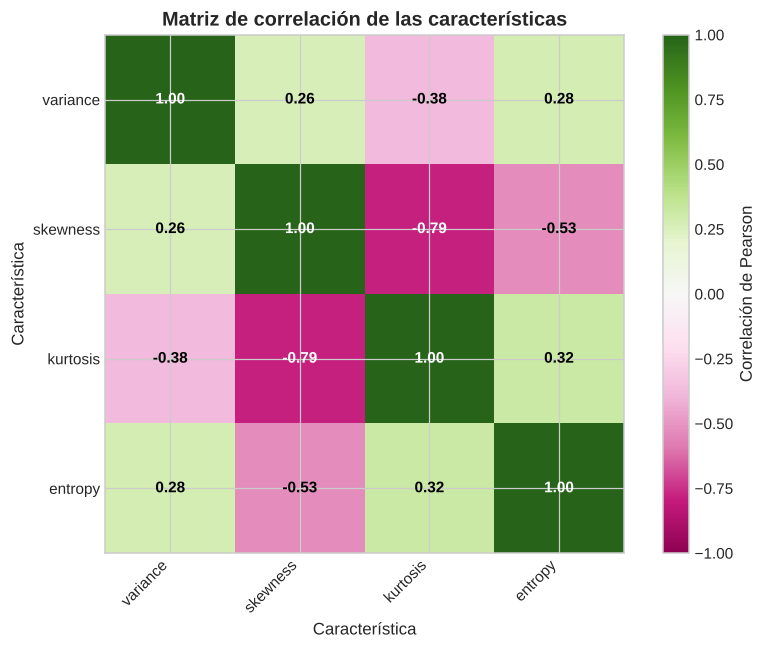

Correlaciones lineales más fuertes entre variables distintas:


abs_correlation
skewness kurtosis         0.786895
         entropy          0.526321
variance kurtosis         0.380850

In [7]:
correlation = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation, cmap='PiYG', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha='right')
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.set_xlabel('Característica')
ax.set_ylabel('Característica')
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        value = correlation.iloc[i, j]
        text_color = 'white' if abs(value) > 0.55 else 'black'
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color=text_color, fontweight='bold')
fig.colorbar(im, ax=ax, label='Correlación de Pearson')
ax.set_title('Matriz de correlación de las características')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '03_matriz_correlacion.png', dpi=300, bbox_inches='tight')
plt.show()

print('Correlaciones lineales más fuertes entre variables distintas:')
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
display(upper.abs().sort_values(ascending=False).head(3).rename('abs_correlation').to_frame())

### Lectura de los resultados observados

En este dataset, la relación lineal más notable es entre **asimetría y curtosis**, con una correlación aproximada de `-0.79`: cuando una aumenta, la otra tiende a disminuir. También aparece una asociación negativa moderada entre asimetría y entropía, cercana a `-0.53`. Las asociaciones de varianza con las demás características son débiles o moderadas.

Esto sugiere que algunos descriptores contienen información relacionada, pero no implica que uno pueda sustituir completamente al otro. La correlación se calcula sin usar la etiqueta y, por tanto, describe la geometría de los predictores, no su capacidad predictiva directa. Además, una correlación alta no invalida automáticamente la regresión logística: el modelo puede seguir clasificando bien, aunque la interpretación aislada de dos coeficientes correlacionados debe hacerse con cautela.

# 1.9 Separación de datos y prevención de *data leakage*

Se separan los predictores `X` de la etiqueta `y` y después se crea un conjunto de prueba estratificado. El test debe permanecer apartado hasta la evaluación final (sección 3.6).

## ¿Qué es la estandarización?

Para cada característica se calcula, usando solo el entrenamiento, la transformación:

$$z = \\frac{x - \\mu_{train}}{\\sigma_{train}}.$$

El resultado tiene aproximadamente media `0` y desviación estándar `1` en los datos de entrenamiento.

## ¿Por qué aplicarla?

La regresión logística aprende una combinación `w^T x + b`. Si una variable tiene valores de decenas y otra de unidades, el optimizador observa una superficie mal condicionada: algunos coeficientes necesitan ser artificialmente pequeños y el entrenamiento puede tardar más o ser menos estable. La estandarización pone las variables en una escala comparable, hace más razonable comparar magnitudes de coeficientes y favorece la regularización.

## ¿Qué pasa si no se hace?

El modelo todavía podría funcionar, pero la convergencia puede ser más lenta, los coeficientes serían menos comparables y la penalización L2 afectaría de forma desigual a las variables. Además, si se calcula `mean` y `std` usando todo el dataset antes de la validación, se filtra información de los pliegues de validación: eso es *data leakage* y produce una estimación demasiado optimista.

Por eso `StandardScaler` se incluye dentro de `Pipeline`: en cada pliegue se ajusta únicamente con la parte de entrenamiento.

In [8]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f'Train: {len(X_train):,} observaciones ({len(X_train) / len(df):.0%})')
print(f'Test:  {len(X_test):,} observaciones ({len(X_test) / len(df):.0%})')
print(f'Proporción de falsos en train: {y_train.mean():.3f}')
print(f'Proporción de falsos en test:  {y_test.mean():.3f}')

Train: 1,097 observaciones (80%)
Test:  275 observaciones (20%)
Proporción de falsos en train: 0.445
Proporción de falsos en test:  0.444


# 1.10 Separabilidad visual por pares de variables

Antes de ajustar la regresión logística, se observan las cuatro características por pares mediante diagramas de dispersión. Cada punto representa un billete y el color representa su clase:

- azul: billete genuino (`0`);
- coral: billete falso (`1`).

Esta matriz permite identificar tendencias lineales, agrupamientos, solapamiento entre clases y posibles valores atípicos. Si dos clases estuvieran separadas claramente por una recta en una proyección, esa pareja de variables tendría evidencia visual compatible con una separación lineal **en esa proyección**.

> Importante: observar mezclas en una proyección 2D no demuestra que el problema completo no sea linealmente separable. El modelo utiliza cuatro variables simultáneamente y una frontera lineal en cuatro dimensiones no puede verse por completo en un gráfico bidimensional. Por ello, esta figura es una herramienta exploratoria, no una prueba definitiva de separabilidad.
### ¿Por qué aparecen histogramas en algunos paneles?

La diagonal no compara dos variables: en cada panel se representa una sola característica contra sí misma. Por eso se utiliza un histograma, que agrupa los valores en intervalos y muestra cuántas observaciones caen en cada intervalo; aquí se normaliza como **densidad** para comparar las formas de las clases aunque tengan tamaños distintos.

Fuera de la diagonal sí hay dos variables diferentes, por ejemplo `variance` contra `skewness`, y cada observación puede ubicarse como un punto `(x, y)`. Esos scatter plots permiten observar agrupamientos, tendencias y solapamiento entre las clases.


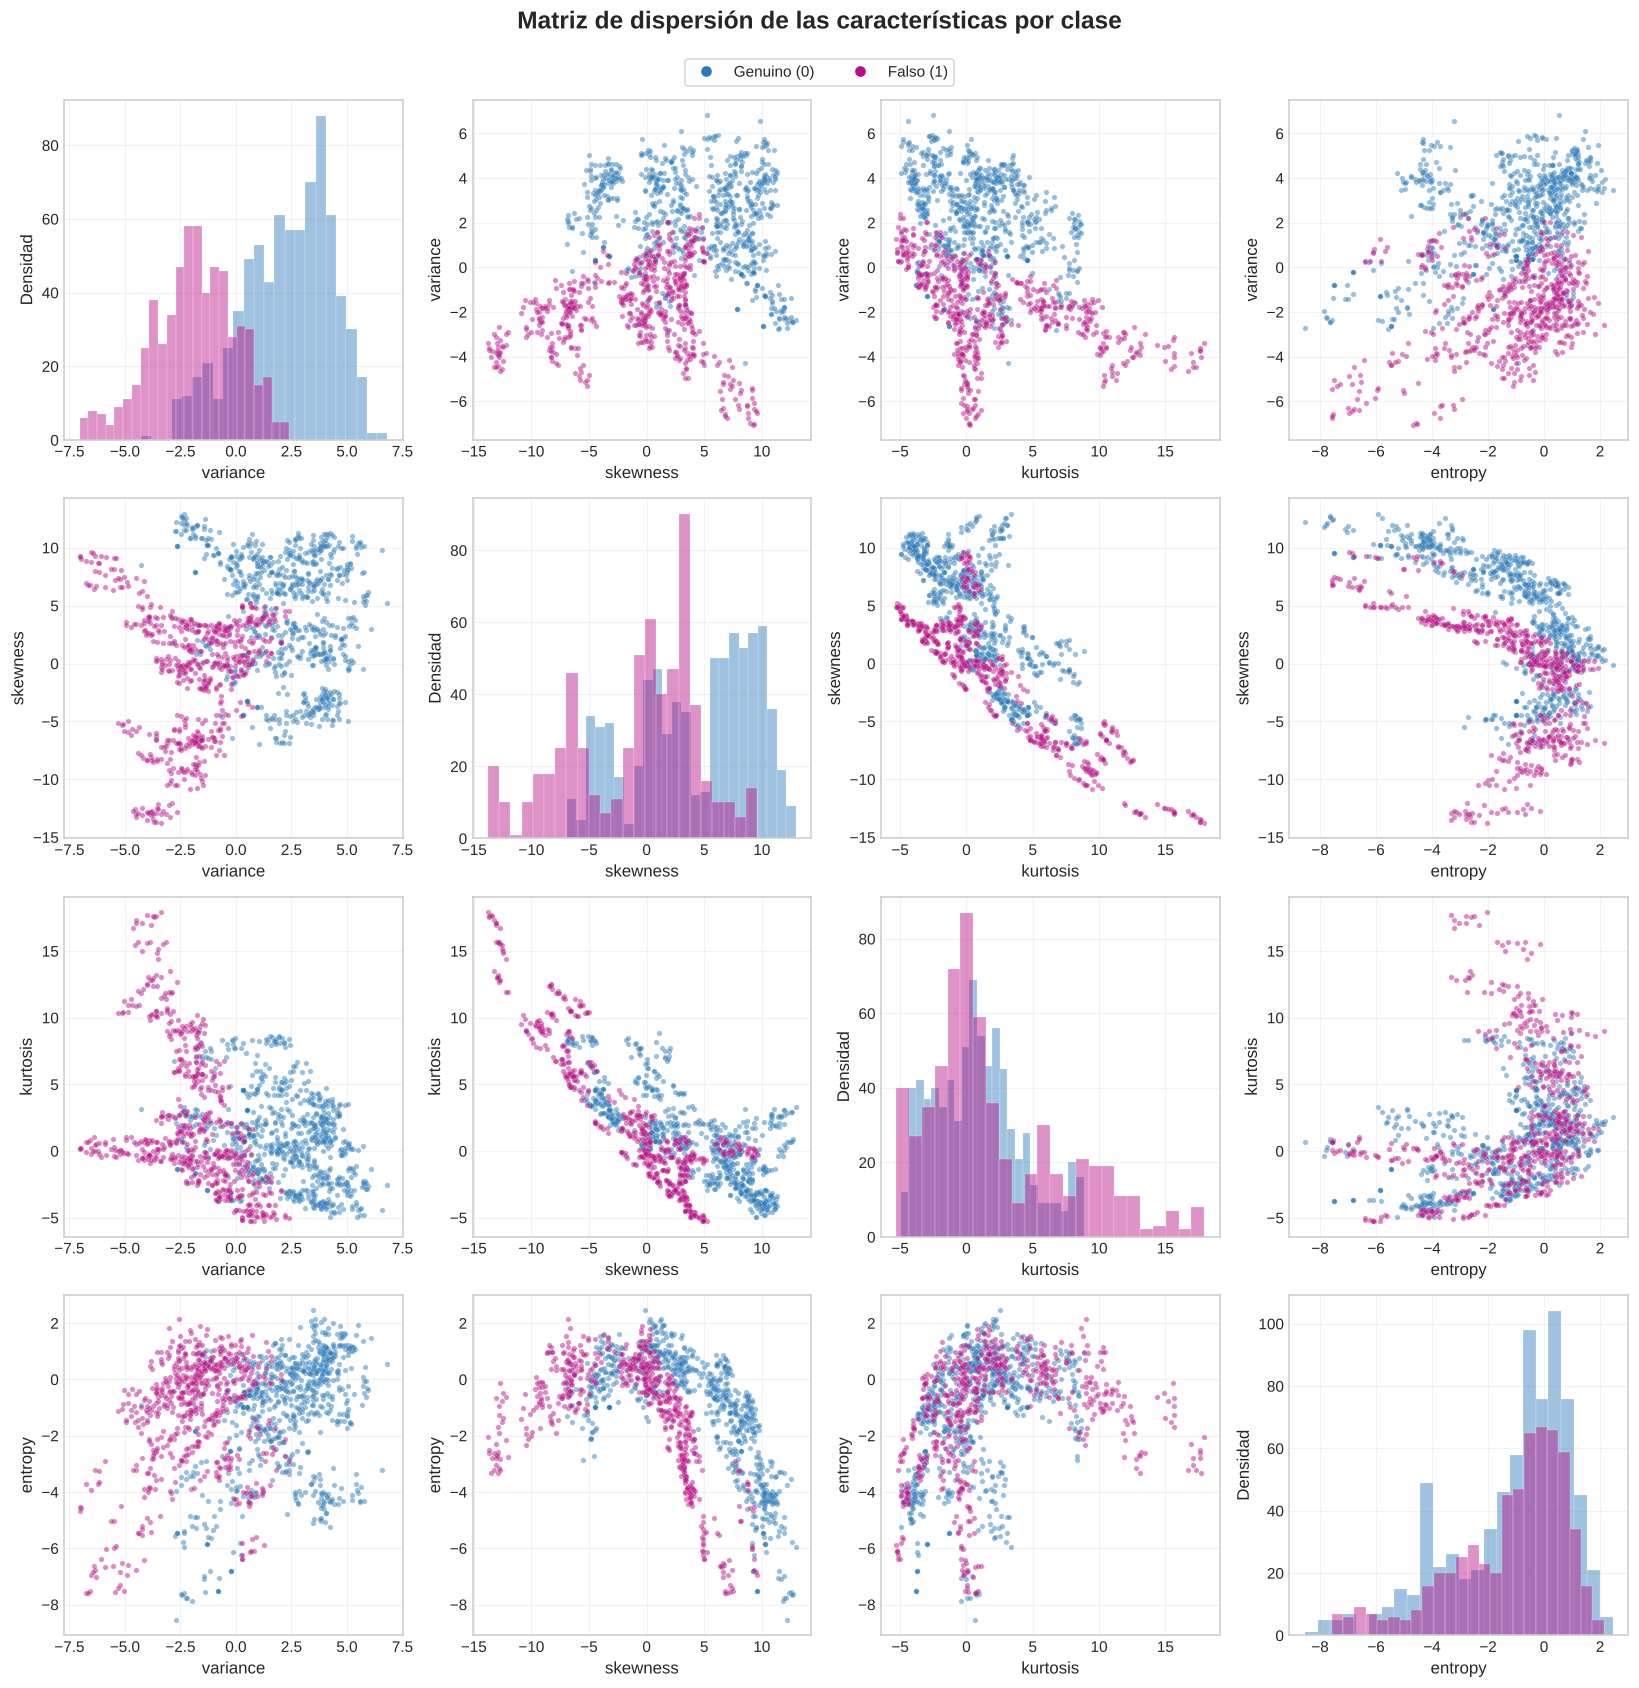

In [9]:
fig, axes = plt.subplots(len(FEATURES), len(FEATURES), figsize=(15, 15))

for row, y_feature in enumerate(FEATURES):
    for col, x_feature in enumerate(FEATURES):
        ax = axes[row, col]
        if row == col:
            # En la diagonal se muestra la distribución univariada de cada característica.
            for label, color in COLORS.items():
                values = df.loc[df[TARGET] == label, x_feature]
                ax.hist(values, bins=24, alpha=0.45, color=color,
                        edgecolor='white', linewidth=0.3, label=CLASS_LABELS[label])
            ax.set_ylabel('Densidad' if col == 0 else '')
        else:
            # Fuera de la diagonal se comparan dos variables y se conserva la clase.
            for label, color in COLORS.items():
                subset = df[df[TARGET] == label]
                ax.scatter(
                    subset[x_feature], subset[y_feature],
                    s=12, alpha=0.48, color=color,
                    edgecolors='white', linewidths=0.2,
                )
        # Cada panel conserva las etiquetas de ambos ejes para poder interpretarlo
        # de forma independiente al exportarlo o recortarlo del notebook.
        ax.set_xlabel(x_feature)
        ax.set_ylabel('Densidad' if row == col else y_feature)
        ax.grid(alpha=0.22)

handles = [
    plt.Line2D([0], [0], marker='o', color='w', label=CLASS_LABELS[label],
               markerfacecolor=color, markersize=8)
    for label, color in COLORS.items()
]
fig.legend(handles=handles, loc='upper center', ncol=2,
           bbox_to_anchor=(0.5, 0.995), frameon=True)
fig.suptitle('Matriz de dispersión de las características por clase',
             y=1.02, fontsize=16, fontweight='bold')
fig.tight_layout()
fig.savefig(PLOTS_DIR / '04_matriz_dispersion_por_clase.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.11 Regresión logística: teoría y elección del modelo

La regresión logística es un clasificador discriminativo lineal. Primero calcula una puntuación lineal:

$$z = w_1x_1 + w_2x_2 + w_3x_3 + w_4x_4 + b,$$

luego la convierte en probabilidad mediante la función sigmoide:

$$P(y=1\\mid x) = \\sigma(z) = \\frac{1}{1 + e^{-z}}.$$

Con el umbral usual de `0.5`, predice falso cuando la probabilidad estimada es al menos `0.5`; equivalentemente, cuando `z >= 0`. El entrenamiento minimiza la pérdida logarítmica y, por defecto, usa regularización L2 para evitar coeficientes excesivamente grandes.

## ¿Por qué usarla como modelo base?

- Es adecuada para una etiqueta binaria.
- Es rápida y reproducible en solo cuatro dimensiones.
- Sus coeficientes permiten interpretar la dirección y fuerza relativa de cada característica estandarizada.
- Proporciona una referencia lineal clara antes de comparar con el modelo no lineal (sección 2).

## ¿Por qué `lbfgs`?

`lbfgs` es un optimizador cuasi-Newton que aproxima la curvatura de la función objetivo usando memoria limitada. Es una elección sólida para problemas pequeños o medianos, con variables continuas, pérdida suave y regularización L2. En este dataset de 1,372 filas y cuatro predictores ofrece una solución estable sin necesitar un algoritmo especializado para datos dispersos.

## ¿Por qué `max_iter=2000`?

`max_iter` es el máximo de iteraciones del optimizador, no el número de observaciones ni de épocas del modelo. Se fija en `2000` como margen de seguridad para que todos los pliegues puedan converger aun cuando una partición sea ligeramente más difícil. No significa que siempre se ejecuten 2000 iteraciones: el optimizador se detiene antes si cumple el criterio de convergencia.

In [10]:
logistic_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        solver='lbfgs',
        max_iter=2_000,
        random_state=RANDOM_STATE,
    )),
])

logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_

# 1.12 Validación cruzada estratificada de cinco pliegues

## Definición

La validación cruzada estima cómo puede generalizar un modelo a datos no vistos. En lugar de depender de una única partición, divide `X_train` e `y_train` en cinco subconjuntos o **pliegues**.

## Procedimiento paso a paso

1. `StratifiedKFold` construye cinco particiones conservando aproximadamente la misma proporción de billetes falsos y genuinos en cada una.
2. En la iteración 1 se entrenan el escalador y la regresión logística con los pliegues 2–5; el pliegue 1 se usa para validar.
3. En la iteración 2 se repite el proceso dejando el pliegue 2 para validar.
4. Se continúa hasta que cada observación haya sido validación exactamente una vez.
5. Se calcula cada métrica en el pliegue reservado y finalmente se informa la media y la desviación estándar de los cinco resultados.

## ¿Por qué utilizarla?

Una sola partición puede ser afortunada o difícil. La validación cruzada reduce esa dependencia, aprovecha mejor los datos disponibles para estimar el desempeño y muestra la variabilidad entre particiones. La estratificación es importante porque evita que un pliegue tenga una proporción de falsificaciones muy diferente.

El pipeline se clona y ajusta desde cero en cada iteración. Así, `StandardScaler` nunca aprende la media o desviación del pliegue que está validando.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision_fake': make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall_fake': make_scorer(recall_score, pos_label=1, zero_division=0),
    'f1_fake': make_scorer(f1_score, pos_label=1, zero_division=0),
}

cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1,
)

metric_names = list(scoring)
summary = pd.DataFrame({
    'metric': metric_names,
    'mean': [cv_results[f'test_{metric}'].mean() for metric in metric_names],
    'std': [cv_results[f'test_{metric}'].std(ddof=1) for metric in metric_names],
})
summary['result'] = summary.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1,
)
print('Resumen de validación cruzada (media ± desviación estándar):')
display(summary[['metric', 'result']])

fold_scores = pd.DataFrame({
    metric: cv_results[f'test_{metric}'] for metric in metric_names
}, index=np.arange(1, cv.n_splits + 1))
fold_scores.index.name = 'fold'
print('Resultados de cada pliegue:')
display(fold_scores.round(4))

Resumen de validación cruzada (media ± desviación estándar):


,metric,result
0,accuracy,0.9845 ± 0.0076
1,precision_fake,0.9703 ± 0.0153
2,recall_fake,0.9959 ± 0.0056
3,f1_fake,0.9829 ± 0.0084


Resultados de cada pliegue:


,accuracy,precision_fake,recall_fake,f1_fake
fold,,,,
1,0.9773,0.9515,1.0000,0.9751
2,0.9864,0.9798,0.9898,0.9848
3,0.9863,0.9703,1.0000,0.9849
4,0.9772,0.9600,0.9897,0.9746
5,0.9954,0.9898,1.0000,0.9949


# 1.13 Interpretación de los resultados de validación

La **accuracy** es la proporción total de predicciones correctas. La **precision de falsos** responde: de todos los billetes que el modelo marcó como falsos, ¿cuántos eran realmente falsos? El **recall de falsos** responde: de todos los falsos existentes, ¿cuántos detectó? El **F1** es la media armónica de precision y recall, por lo que penaliza que una de ellas sea baja.

La media resume el rendimiento esperado en los pliegues; la desviación estándar refleja cuánto cambia al cambiar la partición. Una desviación pequeña indica resultados estables. El recall de falsos es particularmente relevante operacionalmente porque un falso negativo de esa clase equivale a no detectar una falsificación, aunque la decisión final de costos y umbrales pertenece al análisis comparativo (sección 3).

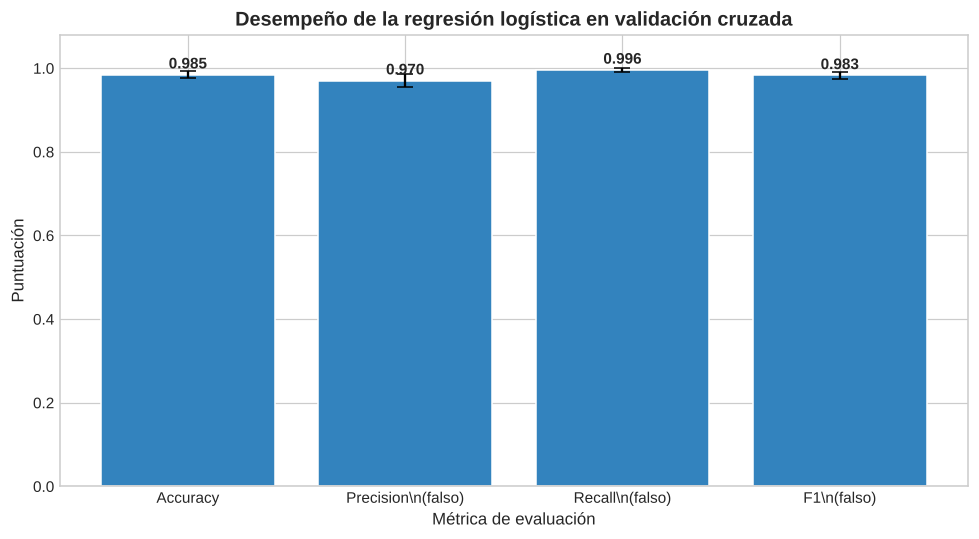

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
metric_labels = {
    'accuracy': 'Accuracy',
    'precision_fake': 'Precision\\n(falso)',
    'recall_fake': 'Recall\\n(falso)',
    'f1_fake': 'F1\\n(falso)',
}
means = summary['mean'].to_numpy()
stds = summary['std'].to_numpy()
x = np.arange(len(metric_names))
bars = ax.bar(x, means, yerr=stds, capsize=5, color=blues(0.68), edgecolor='white')
ax.set_xticks(x, [metric_labels[m] for m in metric_names])
ax.set_xlabel('Métrica de evaluación')
ax.set_ylim(0, 1.08)
ax.set_ylabel('Puntuación')
ax.set_title('Desempeño de la regresión logística en validación cruzada')
for bar, mean in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, mean + 0.015, f'{mean:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '05_metricas_validacion_cruzada.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.14 Ajuste final del modelo

La validación cruzada se utiliza para estimar el comportamiento y decidir si la línea base es razonable. Después se ajusta una última instancia del mismo pipeline utilizando **todo `X_train`**. Esto permite que el modelo aproveche todas las observaciones de entrenamiento antes de la futura evaluación en `X_test`.

El conjunto de prueba no participa en el cálculo de medias, desviaciones, coeficientes ni decisiones del modelo. Solo debe utilizarse una vez en la evaluación final (sección 3.6), para conservar una estimación honesta sobre datos no usados durante el desarrollo.

In [13]:
logistic_pipeline.fit(X_train, y_train)

model = logistic_pipeline.named_steps['model']
coefficients = pd.Series(model.coef_[0], index=FEATURES)
coefficients = coefficients.sort_values(key=np.abs, ascending=False)

print('Modelo final ajustado sobre X_train.')
print(f'Intercepto: {model.intercept_[0]:.4f}')
print('Coeficientes sobre variables estandarizadas:')
display(coefficients.to_frame('coefficient').round(4))

Modelo final ajustado sobre X_train.
Intercepto: -1.3999
Coeficientes sobre variables estandarizadas:


,coefficient
skewness,-4.8065
variance,-4.6660
kurtosis,-4.3989
entropy,0.2580


# 1.15 ¿Cómo se ve el modelo?

La regresión logística trabaja en cuatro dimensiones, por lo que una frontera completa no puede dibujarse fielmente en un gráfico bidimensional. Para visualizarla se hace una **sección del modelo**:

- se eligen `variance` y `skewness` como ejes;
- se fijan `kurtosis` y `entropy` en sus medianas del entrenamiento;
- se calcula la probabilidad predicha en una rejilla de valores;
- la línea de nivel `0.5` representa la frontera de decisión de esa sección.

Los puntos se muestran en sus valores originales, pero la rejilla se transforma dentro del pipeline antes de predecir. Esta figura no reemplaza la evaluación cuantitativa: muestra cómo el modelo combina linealmente dos variables manteniendo las otras constantes.

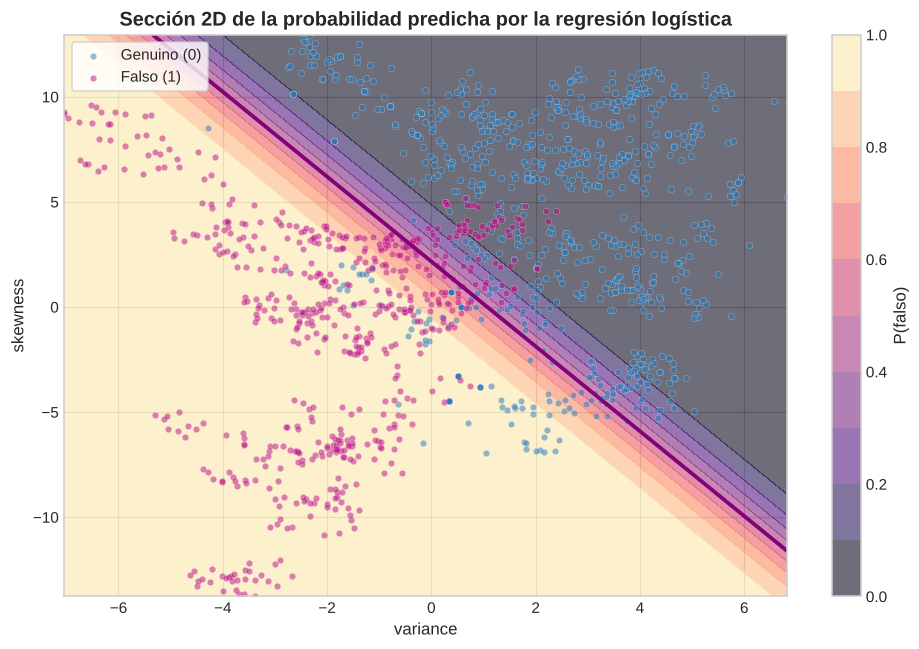

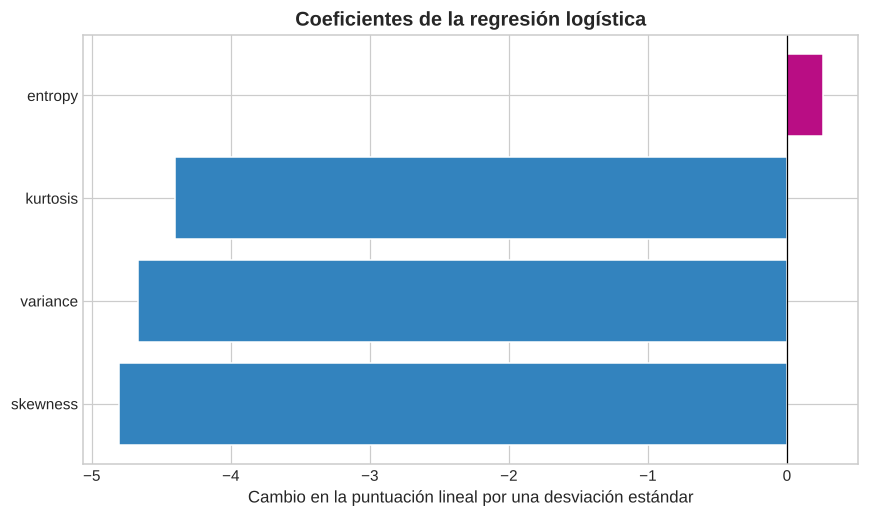

In [14]:
feature_x, feature_y = 'variance', 'skewness'
fixed_features = [feature for feature in FEATURES if feature not in {feature_x, feature_y}]

x_values = np.linspace(X_train[feature_x].min(), X_train[feature_x].max(), 180)
y_values = np.linspace(X_train[feature_y].min(), X_train[feature_y].max(), 180)
xx, yy = np.meshgrid(x_values, y_values)
grid = pd.DataFrame({feature: 0.0 for feature in FEATURES}, index=xx.ravel())
grid[feature_x] = xx.ravel()
grid[feature_y] = yy.ravel()
for feature in fixed_features:
    grid[feature] = X_train[feature].median()
probability = logistic_pipeline.predict_proba(grid)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(9, 6))
levels = np.linspace(0, 1, 11)
contour = ax.contourf(xx, yy, probability, levels=levels, cmap='magma', alpha=0.58)
ax.contour(xx, yy, probability, levels=[0.5], colors=[corals(0.85)], linewidths=2.5)
for label, color in COLORS.items():
    subset = df[df[TARGET] == label]
    ax.scatter(
        subset[feature_x], subset[feature_y], s=18, alpha=0.5,
        color=color, edgecolors='white', linewidths=0.25,
        label=CLASS_LABELS[label],
    )
fig.colorbar(contour, ax=ax, label='P(falso)')
ax.set_xlabel(feature_x)
ax.set_ylabel(feature_y)
ax.set_title('Sección 2D de la probabilidad predicha por la regresión logística')
ax.legend(frameon=True)
plt.tight_layout()
fig.savefig(PLOTS_DIR / '06_superficie_probabilidad_modelo.png', dpi=300, bbox_inches='tight')
plt.show()

# Los coeficientes permiten ver qué dirección favorece la predicción de la clase 1.
fig, ax = plt.subplots(figsize=(8, 4.8))
ordered = coefficients.sort_values()
bar_colors = [blues(0.68) if value < 0 else corals(0.72) for value in ordered]
ax.barh(ordered.index, ordered.values, color=bar_colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Coeficientes de la regresión logística')
ax.set_xlabel('Cambio en la puntuación lineal por una desviación estándar')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '07_coeficientes_regresion_logistica.png', dpi=300, bbox_inches='tight')
plt.show()

# 1.16 Conclusiones detalladas de la sección 1

## Hallazgos del análisis de datos

1. **Calidad y estructura:** el dataset contiene 1,372 billetes descritos por cuatro variables continuas y una etiqueta binaria. No se encontraron valores nulos ni valores no finitos en los predictores. Se detectaron 24 filas duplicadas; se reportan, pero no se eliminan automáticamente porque una fila repetida puede ser una observación válida del conjunto original y eliminarla sin una regla documentada cambiaría la muestra.

2. **Distribución de clases:** hay 762 billetes genuinos (`55.54%`) y 610 falsos (`44.46%`). La diferencia es moderada, no extrema, por lo que el conjunto está razonablemente balanceado. Aun así, se utiliza estratificación para que cada partición conserve una proporción similar y no se depende únicamente de accuracy.

## ¿Por qué se escogieron estas cuatro variables?

3. **Son los predictores definidos por el dataset:** `variance`, `skewness`, `kurtosis` y `entropy` no fueron elegidos arbitrariamente durante este notebook. Son los cuatro descriptores estadísticos de la imagen transformada mediante wavelets que proporciona el conjunto Banknote Authentication. Representan propiedades distintas de la señal visual del billete y condensan información de la imagen en variables numéricas manejables.

4. **Varianza:** aporta información sobre la dispersión de los valores de la imagen transformada. Diferencias en textura, contraste o variabilidad local pueden ayudar a distinguir billetes genuinos de falsificaciones.

5. **Asimetría:** describe si la distribución de intensidades se inclina hacia un lado. Es útil porque dos imágenes pueden tener una dispersión parecida, pero una distribución de intensidades diferente.

6. **Curtosis:** aporta información sobre la concentración central y el peso de las colas de la distribución. Complementa a la varianza y a la asimetría al capturar otra característica de la forma estadística de la imagen.

7. **Entropía:** resume el grado de irregularidad o información presente. Puede capturar diferencias de complejidad visual que no quedan completamente descritas por los momentos anteriores.

8. **Se conservaron las cuatro variables:** el objetivo de esta sección es establecer una línea base reproducible, no hacer selección de características de manera exploratoria. Usar todos los predictores disponibles evita descartar información antes de medir el modelo. Además, solo hay cuatro variables, por lo que el costo computacional y el riesgo de sobrecargar el modelo son bajos. Una selección posterior debería justificarse con un procedimiento dentro de la validación cruzada para no introducir optimismo ni fuga de información.

9. **Relaciones entre variables:** la correlación asimetría-curtosis es aproximadamente `-0.79` y la de asimetría-entropía aproximadamente `-0.53`. Esto indica que algunos descriptores comparten información lineal, pero no significa que sean duplicados perfectos ni que alguno deba eliminarse automáticamente. La correlación no mide relaciones no lineales ni capacidad predictiva directa.

## Preprocesamiento y modelo

10. **Estandarización:** los predictores tienen rangos y desviaciones diferentes. Se estandarizan para que la optimización y la regularización de la regresión logística trabajen en una escala comparable. El `StandardScaler` está dentro del pipeline y se ajusta desde cero en cada pliegue; por eso las medias y desviaciones del pliegue de validación no influyen en el entrenamiento.

11. **Regresión logística:** se escogió como modelo base porque la etiqueta es binaria, el número de predictores es pequeño y el modelo ofrece probabilidades e interpretabilidad. Su frontera lineal permite establecer una referencia clara antes de valorar si el modelo no lineal de la sección 2 captura patrones adicionales. Los coeficientes del ajuste final muestran efectos negativos para variance, skewness y kurtosis, y un efecto positivo menor para entropy; estas direcciones deben interpretarse sobre variables estandarizadas y con cautela debido a la correlación entre predictores. No representan causalidad.

12. **Configuración del optimizador:** `lbfgs` es adecuado para una función objetivo suave, variables continuas y un dataset pequeño. `max_iter=2000` proporciona margen suficiente para que el optimizador converja en cada pliegue; no obliga a ejecutar siempre 2,000 iteraciones, porque se detiene cuando alcanza el criterio de convergencia.

## Evaluación y significado de los resultados

13. **Validación cruzada:** los cinco pliegues generan estimaciones sobre distintas particiones y permiten reportar media y desviación estándar. La media observada del recall de falsos es `0.9959` y su desviación estándar `0.0056`, mientras que el F1 medio es `0.9829 ± 0.0084`. Esto indica un desempeño alto y estable de la línea base en los pliegues, pero no prueba por sí solo que la regresión logística sea mejor que el segundo modelo.

14. **Ajuste final:** después de estimar el desempeño mediante validación cruzada, el pipeline se ajusta con todo `X_train`. `X_test` permanece reservado para la evaluación conjunta final. Esta separación permite que la comparación entre modelos use datos que no guiaron la selección ni el ajuste.

15. **Conclusión de la sección 1:** la regresión logística constituye una línea base sólida porque utiliza las cuatro variables originales, las escala correctamente, evita fuga de información y se evalúa con un protocolo estratificado. La respuesta a la pregunta global —qué modelo es superior— debe esperar a que el modelo de la sección 2 se evalúe con el mismo protocolo y a que la sección 3 contraste sus recalls, errores y significancia estadística.

16. **Lectura práctica:** si el modelo lineal ya alcanza un recall muy alto, el modelo no lineal solo justificaría su mayor complejidad si mejora de forma consistente el recall o reduce errores relevantes, y si esa mejora es estadísticamente y operacionalmente importante. Si la mejora es mínima, la simplicidad e interpretabilidad de la regresión logística pueden ser ventajas prácticas.

# 2. Modelo no lineal: Random Forest

## 2.0 Alcance

Esta sección cubre:

- implementación y entrenamiento del Modelo 2 (**Random Forest**) bajo *las mismas* particiones que el modelo base (sección 1);
- búsqueda de hiperparámetros mediante **validación cruzada anidada** (validación interna solo sobre el entrenamiento de cada pliegue);
- extracción de **importancia de variables** y de **reglas de decisión** (árbol pequeño, solo con fines interpretativos).

No incluye curvas ROC comparativas, matrices de confusión comparativas ni la prueba t: eso corresponde a la sección 3. Por eso esta sección **no toca el conjunto de prueba** y deja guardados los resultados por pliegue en el mismo formato que usa la sección 1.

### Protocolo común

| Elemento | Valor |
|---|---|
| Semilla | `random_state=42` |
| Partición train/test | 80 % / 20 %, estratificada |
| Validación externa | `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sobre `X_train` |
| Métrica principal | recall de la clase falsa (`1`) |
| Métricas complementarias | accuracy, precision (falso), F1 (falso) |

In [15]:
from itertools import product
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# --- Constantes comunes a todo el estudio ---
FEATURES = ['variance', 'skewness', 'kurtosis', 'entropy']
TARGET = 'is_fake'
RANDOM_STATE = 42
PLOTS_DIR = Path('../report/plots')
RESULTS_DIR = Path('../results/random_forest')
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

blues = plt.get_cmap('Blues')
corals = plt.get_cmap('RdPu')
COLORS = {0: blues(0.72), 1: corals(0.72)}
CLASS_LABELS = {0: 'Genuino (0)', 1: 'Falso (1)'}

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'figure.dpi': 110,
})

# 2.1 Carga de datos y partición (idéntica a la de la sección 1)

Se usa la **misma** llamada a `train_test_split` (`test_size=0.20`, `stratify=y`, `random_state=42`). Con los mismos argumentos y el mismo orden del archivo, las filas de entrenamiento y prueba son exactamente las de la sección 1, lo que garantiza que la comparación entre modelos sea justa.

El conjunto `X_test` queda apartado: aquí **no se usa**.

In [16]:
data_path = Path('../data/data_banknote_authentication.txt')
if not data_path.exists():
    raise FileNotFoundError(f'No se encontró el dataset en: {data_path.resolve()}')

df = pd.read_csv(data_path, header=None, names=FEATURES + [TARGET])
df[TARGET] = pd.to_numeric(df[TARGET], errors='raise').astype(int)

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f'Train: {len(X_train):,} | Test (sin usar): {len(X_test):,}')
print(f'Proporción de falsos en train: {y_train.mean():.3f}')

Train: 1,097 | Test (sin usar): 275
Proporción de falsos en train: 0.445


# 2.2 Random Forest: teoría breve y decisión sobre el escalado

Un **Random Forest** es un conjunto (*ensemble*) de $B$ árboles de decisión entrenados sobre muestras *bootstrap* del entrenamiento. En cada nodo, cada árbol considera solo un subconjunto aleatorio de `max_features` variables para elegir la mejor partición. La predicción final es el promedio de las probabilidades de los árboles:

$$\hat{P}(y=1\mid x)=\frac{1}{B}\sum_{b=1}^{B}\hat{P}_b(y=1\mid x),\qquad \hat{y}=\mathbb{1}\left[\hat{P}(y=1\mid x)\ge 0.5\right].$$

Cada árbol divide el espacio con cortes de la forma $x_j \le t$, por lo que la frontera resultante es **no lineal y por tramos ortogonales a los ejes**. Promediar muchos árboles decorrelacionados reduce la varianza respecto a un solo árbol.

### ¿Se escala?

**No es necesario.** Los cortes $x_j \le t$ solo dependen del orden de los valores, no de su escala; estandarizar no cambia las particiones posibles. Por eso aquí el *pipeline* no incluye `StandardScaler`. Esto además elimina por construcción cualquier riesgo de *data leakage* por escalado. (Si se quisiera uniformidad con la sección 1, añadirlo no cambiaría los resultados.)

# 2.3 Espacio de hiperparámetros

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `n_estimators` | 100, 300 | Número de árboles $B$. Más árboles estabilizan la predicción, con rendimientos decrecientes. |
| `max_depth` | 3, 5, 8, `None` | Profundidad máxima. Limita la complejidad de cada árbol (sobreajuste vs. subajuste). |
| `min_samples_leaf` | 1, 3, 5 | Mínimo de observaciones por hoja. Valores altos suavizan la frontera. |
| `max_features` | `'sqrt'`, `None` | Variables consideradas por corte. `'sqrt'` (=2 de 4) decorrelaciona árboles; `None` usa las 4. |

Son $2\times4\times3\times2=48$ combinaciones. Se elige un espacio moderado porque el dataset es pequeño (4 variables) y la meta es documentar un ajuste reproducible, no exprimir centésimas.

### Criterio de selección (validación interna)

El criterio sigue la métrica principal del proyecto: **mayor recall medio de la clase falsa**. Como en este dataset muchas combinaciones empatan en recall (≈1.0), se desempata con **mayor F1 de la clase falsa** y, si persiste el empate, con el **modelo más simple** (menos árboles, menor profundidad). Así la elección no depende del orden en que aparecen las combinaciones.

In [17]:
PARAM_GRID = {
    'n_estimators': [100, 300],
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [1, 3, 5],
    'max_features': ['sqrt', None],
}

INNER_SCORING = {
    'recall_fake': 'recall',   # pos_label=1 por defecto (clase falsa)
    'f1_fake': 'f1',
}


def select_best(cv_results_):
    # Elige el índice ganador: máx. recall -> máx. F1 -> modelo más simple.
    res = pd.DataFrame(cv_results_)
    res['depth_num'] = res['param_max_depth'].apply(lambda d: np.inf if d is None else d)
    res['recall_r'] = res['mean_test_recall_fake'].round(10)
    res['f1_r'] = res['mean_test_f1_fake'].round(10)
    order = res.sort_values(
        ['recall_r', 'f1_r', 'param_n_estimators', 'depth_num'],
        ascending=[False, False, True, True],
    )
    return int(order.index[0])


def make_search(inner_seed=RANDOM_STATE):
    # GridSearchCV con validación interna estratificada de 3 pliegues.
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=inner_seed)
    return GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        param_grid=PARAM_GRID,
        scoring=INNER_SCORING,
        refit=select_best,
        cv=inner_cv,
        n_jobs=-1,
    )

# 2.4 Validación cruzada anidada (sin tocar el test)

## Estructura

- **Bucle externo** (5 pliegues estratificados, idéntico al de la sección 1): estima el desempeño que se reportará y se comparará con la regresión logística.
- **Bucle interno** (3 pliegues estratificados *dentro del entrenamiento de cada pliegue externo*): elige los hiperparámetros.

El pliegue externo de validación **nunca participa** en la elección de hiperparámetros. Si el ajuste se hiciera sobre los mismos pliegues que se reportan, el resultado quedaría optimista (fuga por selección de modelo).

Se recorre el bucle externo manualmente para poder guardar, por pliegue: las métricas, los hiperparámetros elegidos, las probabilidades fuera de muestra y la importancia de variables. Los pliegues salen del mismo `StratifiedKFold(5, shuffle=True, random_state=42)` aplicado sobre el mismo `X_train` que se usó en la sección 1.

In [18]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_rows, oof_rows, importance_rows = [], [], []

for fold, (idx_tr, idx_val) in enumerate(outer_cv.split(X_train, y_train), start=1):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

    search = make_search()
    search.fit(X_tr, y_tr)                  # el ajuste usa SOLO el entrenamiento del pliegue
    best_model = search.best_estimator_

    pred = best_model.predict(X_val)
    proba = best_model.predict_proba(X_val)[:, 1]

    fold_rows.append({
        'fold': fold,
        'accuracy': accuracy_score(y_val, pred),
        'precision_fake': precision_score(y_val, pred, pos_label=1, zero_division=0),
        'recall_fake': recall_score(y_val, pred, pos_label=1, zero_division=0),
        'f1_fake': f1_score(y_val, pred, pos_label=1, zero_division=0),
        **{f'best_{k}': v for k, v in search.best_params_.items()},
    })
    oof_rows.append(pd.DataFrame({
        'fold': fold, 'index': X_val.index, 'y_true': y_val.to_numpy(),
        'y_pred': pred, 'proba_fake': proba,
    }))
    importance_rows.append(pd.Series(best_model.feature_importances_, index=FEATURES, name=fold))
    print(f'Pliegue {fold}: recall={fold_rows[-1]["recall_fake"]:.4f} '
          f'f1={fold_rows[-1]["f1_fake"]:.4f} | mejores: {search.best_params_}')

fold_scores_rf = pd.DataFrame(fold_rows).set_index('fold')
oof_predictions = pd.concat(oof_rows, ignore_index=True)
fold_importances = pd.DataFrame(importance_rows)

Pliegue 1: recall=1.0000 f1=0.9899 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


Pliegue 2: recall=1.0000 f1=1.0000 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}


Pliegue 3: recall=0.9898 f1=0.9700 | mejores: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


Pliegue 4: recall=1.0000 f1=1.0000 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}


Pliegue 5: recall=0.9897 f1=0.9796 | mejores: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


# 2.5 Resultados por pliegue y resumen

La tabla por pliegue tiene **las mismas columnas de métricas** (`accuracy`, `precision_fake`, `recall_fake`, `f1_fake`) y el mismo índice `fold` que la sección 1, de modo que la sección 3 pueda emparejar pliegue a pliegue para la prueba t. Las columnas `best_*` documentan los hiperparámetros elegidos en cada pliegue.

In [19]:
metric_names = ['accuracy', 'precision_fake', 'recall_fake', 'f1_fake']

summary_rf = pd.DataFrame({
    'metric': metric_names,
    'mean': [fold_scores_rf[m].mean() for m in metric_names],
    'std': [fold_scores_rf[m].std(ddof=1) for m in metric_names],
})
summary_rf['result'] = summary_rf.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)

print('Random Forest — validación cruzada externa (media ± desviación estándar):')
display(summary_rf[['metric', 'result']])
print('Resultados por pliegue:')
display(fold_scores_rf.round(4))

Random Forest — validación cruzada externa (media ± desviación estándar):


,metric,result
0,accuracy,0.9890 ± 0.0119
1,precision_fake,0.9801 ± 0.0209
2,recall_fake,0.9959 ± 0.0056
3,f1_fake,0.9879 ± 0.0131


Resultados por pliegue:


,accuracy,precision_fake,recall_fake,f1_fake,best_max_depth,best_max_features,best_min_samples_leaf,best_n_estimators
fold,,,,,,,,
1,0.9909,0.9800,1.0000,0.9899,8,sqrt,1,300
2,1.0000,1.0000,1.0000,1.0000,8,sqrt,1,100
3,0.9726,0.9510,0.9898,0.9700,5,sqrt,1,300
4,1.0000,1.0000,1.0000,1.0000,8,sqrt,1,100
5,0.9817,0.9697,0.9897,0.9796,8,sqrt,1,300


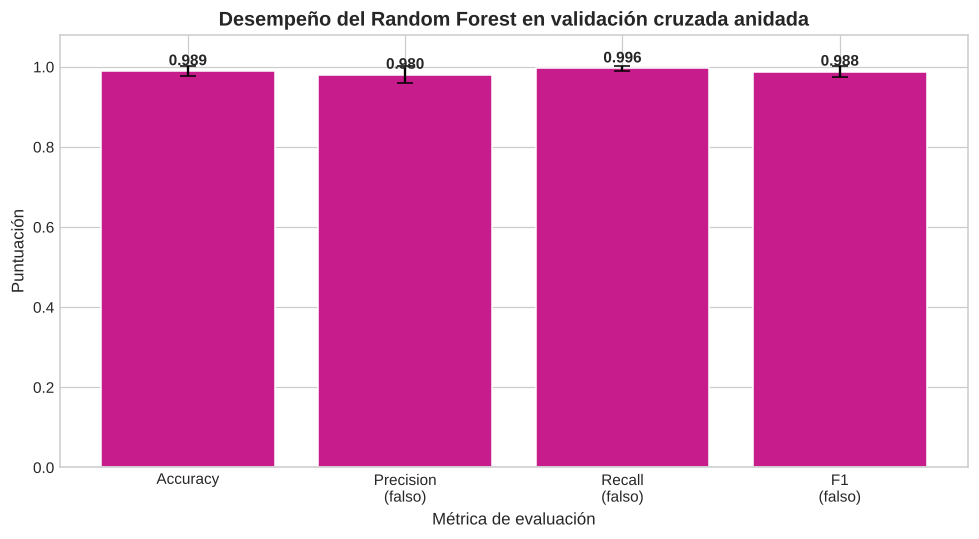

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
metric_labels = {
    'accuracy': 'Accuracy',
    'precision_fake': 'Precision\n(falso)',
    'recall_fake': 'Recall\n(falso)',
    'f1_fake': 'F1\n(falso)',
}
x = np.arange(len(metric_names))
bars = ax.bar(x, summary_rf['mean'], yerr=summary_rf['std'], capsize=5,
              color=corals(0.68), edgecolor='white')
ax.set_xticks(x, [metric_labels[m] for m in metric_names])
ax.set_xlabel('Métrica de evaluación')
ax.set_ylabel('Puntuación')
ax.set_ylim(0, 1.08)
ax.set_title('Desempeño del Random Forest en validación cruzada anidada')
for bar, mean in zip(bars, summary_rf['mean']):
    ax.text(bar.get_x() + bar.get_width() / 2, mean + 0.015, f'{mean:.3f}',
            ha='center', fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '08_rf_metricas_validacion_cruzada.png', dpi=300, bbox_inches='tight')
plt.show()

# 2.6 Hiperparámetros elegidos y estabilidad del ajuste

Si los cinco pliegues eligen configuraciones parecidas, el ajuste es estable. Si cambian mucho, significa que varias configuraciones rinden prácticamente igual en este dataset (algo esperable con 4 variables y clases bien separables) y la elección concreta importa poco.

In [21]:
best_cols = [c for c in fold_scores_rf.columns if c.startswith('best_')]
display(fold_scores_rf[best_cols])

print('Frecuencia de cada valor elegido (sobre los 5 pliegues):')
for col in best_cols:
    print(f'  {col}: {fold_scores_rf[col].astype(str).value_counts().to_dict()}')

,best_max_depth,best_max_features,best_min_samples_leaf,best_n_estimators
fold,,,,
1,8,sqrt,1,300
2,8,sqrt,1,100
3,5,sqrt,1,300
4,8,sqrt,1,100
5,8,sqrt,1,300


Frecuencia de cada valor elegido (sobre los 5 pliegues):
  best_max_depth: {'8': 4, '5': 1}
  best_max_features: {'sqrt': 5}
  best_min_samples_leaf: {'1': 5}
  best_n_estimators: {'300': 3, '100': 2}


# 2.7 Modelo final e importancia de variables

## Ajuste final

Igual que en la sección 1, tras estimar el desempeño con el bucle externo se ajusta **una última instancia sobre todo `X_train`**, repitiendo la búsqueda interna sobre ese conjunto completo. Esta instancia es la que se usará en la sección 3 para la evaluación en `X_test`.

## Importancia de variables

Se usa la **importancia por impureza** (*mean decrease in impurity*): cuánto reduce cada variable, en promedio, la impureza de Gini en los cortes donde participa, normalizada para sumar 1. Se reporta la del modelo final y la media ± desviación entre los 5 modelos de pliegue (como medida de estabilidad).

> Precaución de interpretación: la importancia por impureza se calcula con datos de entrenamiento y puede repartirse entre variables correlacionadas (aquí, `skewness` y `kurtosis` tienen correlación ≈ −0.79). Indica qué usa el modelo, no una relación causal.

In [22]:
final_search = make_search()
final_search.fit(X_train, y_train)
rf_final = final_search.best_estimator_

print('Hiperparámetros del modelo final (búsqueda interna sobre todo X_train):')
print(final_search.best_params_)

final_importance = pd.Series(rf_final.feature_importances_, index=FEATURES).sort_values(ascending=False)
importance_table = pd.DataFrame({
    'final': final_importance,
    'cv_mean': fold_importances.mean().reindex(final_importance.index),
    'cv_std': fold_importances.std(ddof=1).reindex(final_importance.index),
})
display(importance_table.round(4))

Hiperparámetros del modelo final (búsqueda interna sobre todo X_train):
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,final,cv_mean,cv_std
variance,0.5592,0.5644,0.0184
skewness,0.2321,0.2353,0.0133
kurtosis,0.1528,0.1437,0.0116
entropy,0.0559,0.0566,0.0041


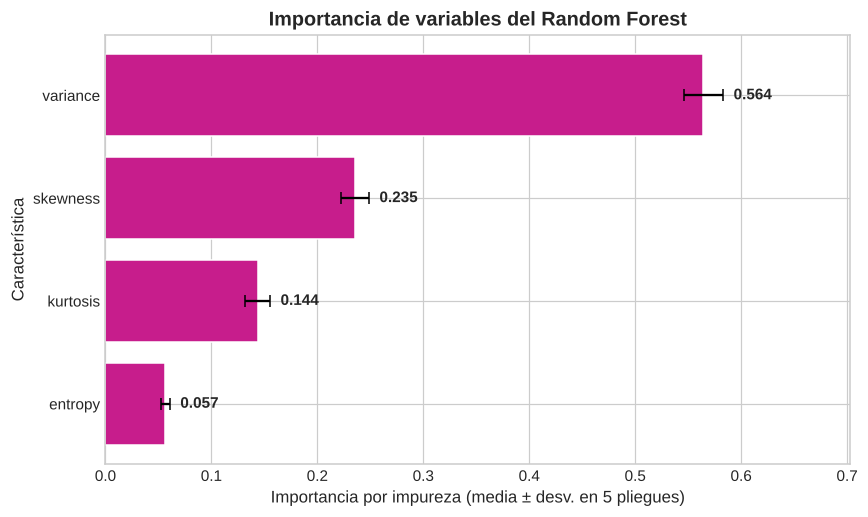

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.8))
order = importance_table.index[::-1]
ax.barh(order, importance_table.loc[order, 'cv_mean'],
        xerr=importance_table.loc[order, 'cv_std'], capsize=4,
        color=corals(0.68), edgecolor='white')
for i, feat in enumerate(order):
    ax.text(importance_table.loc[feat, 'cv_mean'] + importance_table.loc[feat, 'cv_std'] + 0.01,
            i, f"{importance_table.loc[feat, 'cv_mean']:.3f}", va='center', fontweight='bold')
ax.set_xlabel('Importancia por impureza (media ± desv. en 5 pliegues)')
ax.set_ylabel('Característica')
ax.set_title('Importancia de variables del Random Forest')
ax.set_xlim(0, importance_table['cv_mean'].max() + importance_table['cv_std'].max() + 0.12)
plt.tight_layout()
fig.savefig(PLOTS_DIR / '09_rf_importancia_variables.png', dpi=300, bbox_inches='tight')
plt.show()

# 2.8 Reglas de decisión: árbol pequeño interpretable

Un bosque de cientos de árboles no se puede leer. Para ilustrar **qué tipo de reglas** aprende el modelo, se ajusta un único `DecisionTreeClassifier` de profundidad 3 sobre `X_train`. 

Este árbol es **solo explicativo**: no forma parte de la comparación estadística ni se evalúa con el test. Cada hoja corresponde a una conjunción de cortes del tipo $x_j \le t$, que se puede leer como una regla *si–entonces*.

|--- variance <= 0.77
|   |--- skewness <= 5.16
|   |   |--- variance <= 0.32
|   |   |   |--- weights: [20.00, 393.00] class: 1
|   |   |--- variance >  0.32
|   |   |   |--- weights: [22.00, 29.00] class: 1
|   |--- skewness >  5.16
|   |   |--- variance <= -3.43
|   |   |   |--- weights: [1.00, 31.00] class: 1
|   |   |--- variance >  -3.43
|   |   |   |--- weights: [96.00, 1.00] class: 0
|--- variance >  0.77
|   |--- kurtosis <= -4.46
|   |   |--- variance <= 3.30
|   |   |   |--- weights: [0.00, 16.00] class: 1
|   |   |--- variance >  3.30
|   |   |   |--- weights: [8.00, 0.00] class: 0
|   |--- kurtosis >  -4.46
|   |   |--- variance <= 1.74
|   |   |   |--- weights: [80.00, 16.00] class: 0
|   |   |--- variance >  1.74
|   |   |   |--- weights: [382.00, 2.00] class: 0



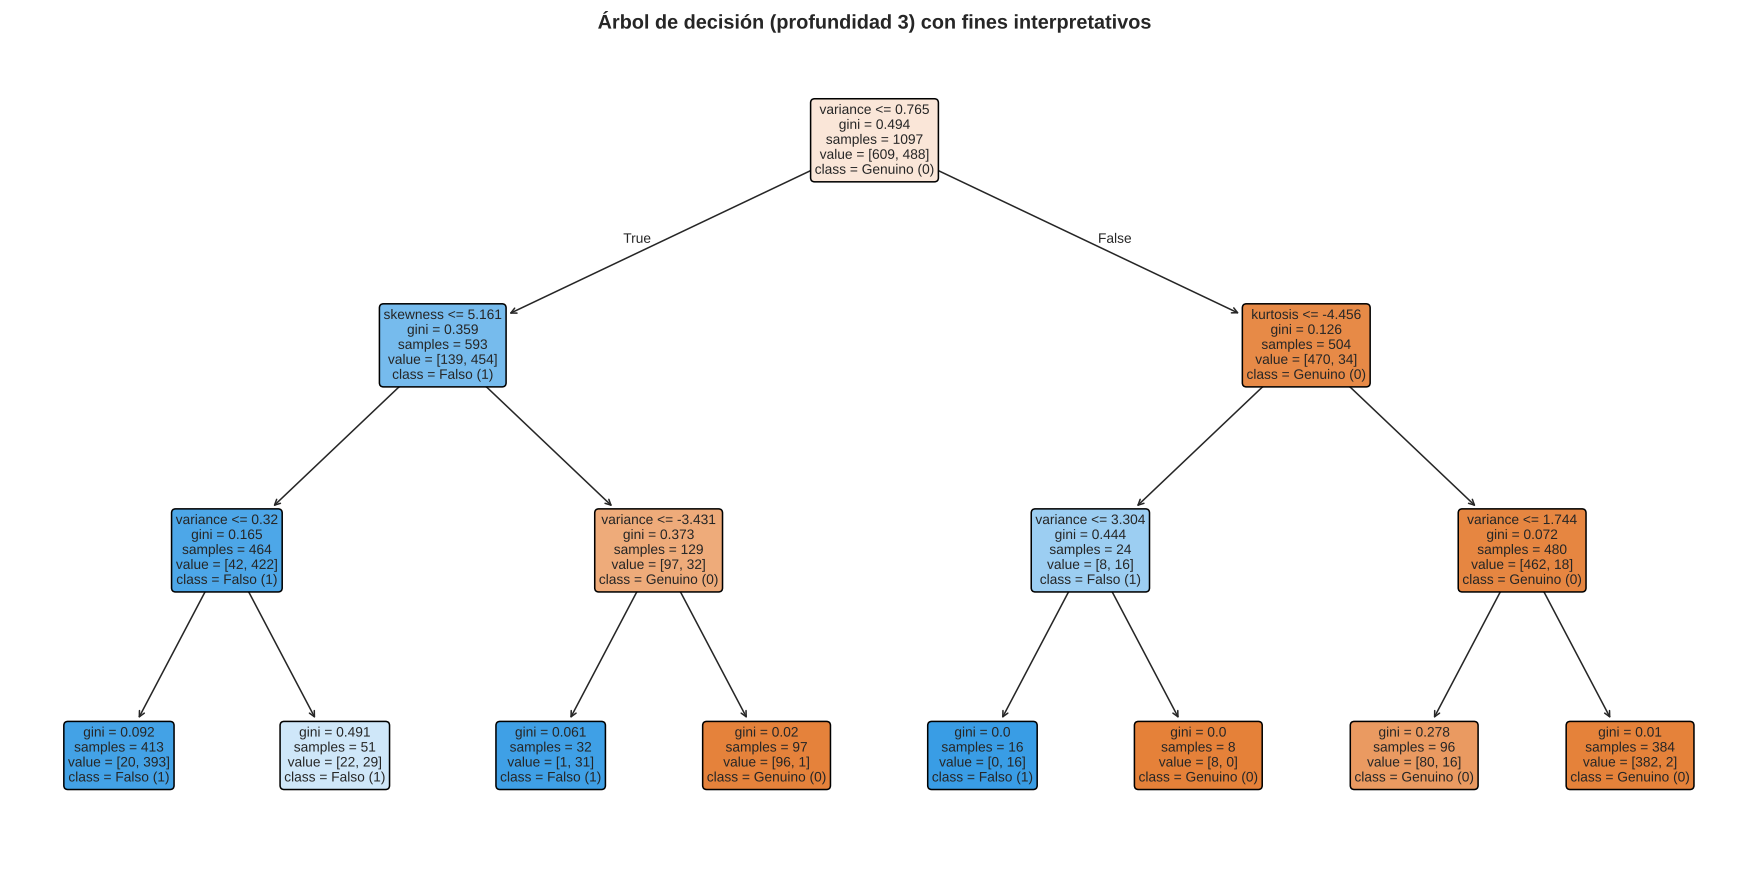

In [24]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

rules_text = export_text(tree, feature_names=FEATURES, show_weights=True)
print(rules_text)
(RESULTS_DIR / '07_reglas_arbol_decision.txt').write_text(rules_text, encoding='utf-8')

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree, feature_names=FEATURES, class_names=[CLASS_LABELS[0], CLASS_LABELS[1]],
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=9, ax=ax)
ax.set_title('Árbol de decisión (profundidad 3) con fines interpretativos')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '10_arbol_decision_reglas.png', dpi=300, bbox_inches='tight')
plt.show()

# 2.9 Exportación de resultados

Se guardan, en `../results/random_forest/`:

| Archivo | Contenido |
|---|---|
| `01_rf_resumen_cv.csv` | Media y desviación de cada métrica |
| `02_rf_mediciones_por_pliegue.csv` | Métricas e hiperparámetros por pliegue (para la prueba t emparejada) |
| `03_rf_predicciones_fuera_de_muestra.csv` | Probabilidad de falso y predicción de cada observación de `X_train` cuando estuvo en validación |
| `04_rf_importancia_variables.csv` | Importancia final y por pliegue |
| `05_rf_hiperparametros_finales.json` | Hiperparámetros del modelo final |
| `06_modelo_rf_final.joblib` | Modelo final ajustado sobre todo `X_train` (sin haber visto `X_test`) |

In [25]:
import json

summary_rf.to_csv(RESULTS_DIR / '01_rf_resumen_cv.csv', index=False)
fold_scores_rf.to_csv(RESULTS_DIR / '02_rf_mediciones_por_pliegue.csv')
oof_predictions.to_csv(RESULTS_DIR / '03_rf_predicciones_fuera_de_muestra.csv', index=False)
importance_table.to_csv(RESULTS_DIR / '04_rf_importancia_variables.csv')
(RESULTS_DIR / '05_rf_hiperparametros_finales.json').write_text(
    json.dumps(final_search.best_params_, indent=2, default=str), encoding='utf-8')
joblib.dump(rf_final, RESULTS_DIR / '06_modelo_rf_final.joblib')

print('Archivos guardados en', RESULTS_DIR.resolve())
for p in sorted(RESULTS_DIR.iterdir()):
    print(' -', p.name)

Archivos guardados en proyecto/results/random_forest
 - 01_rf_resumen_cv.csv
 - 02_rf_mediciones_por_pliegue.csv
 - 03_rf_predicciones_fuera_de_muestra.csv
 - 04_rf_importancia_variables.csv
 - 05_rf_hiperparametros_finales.json
 - 06_modelo_rf_final.joblib
 - 07_reglas_arbol_decision.txt


# 2.10 Conclusiones del Random Forest

## Desempeño

El Random Forest, evaluado con validación cruzada anidada de cinco pliegues estratificados, obtuvo un **recall de la clase falsa de 0.9959 ± 0.0056**, un F1 de 0.9879 ± 0.0131, una precision de 0.9801 ± 0.0209 y una accuracy de 0.9890 ± 0.0119. Las diferencias entre pliegues provienen de muy pocas observaciones: los pliegues 3 y 5 tuvieron aproximadamente un falso negativo cada uno (recall ≈ 0.99), mientras que los pliegues 2 y 4 clasificaron sin ningún error. La desviación estándar baja indica que el desempeño es estable frente a la partición.

## Hiperparámetros

La búsqueda interna fue estable: `max_features='sqrt'` y `min_samples_leaf=1` se eligieron en los cinco pliegues, y `max_depth=8` en cuatro de cinco. Solo `n_estimators` alternó entre 100 y 300. Esto sugiere que, en un problema de solo cuatro variables y clases bien separables, varias configuraciones rinden prácticamente igual y la elección concreta tiene poco efecto. El modelo final (ajustado sobre todo `X_train`) eligió `max_depth=None`, `max_features='sqrt'`, `min_samples_leaf=1` y `n_estimators=300`, compatible con lo observado en los pliegues.

## Variables

`variance` domina la importancia por impureza (≈ 0.56), seguida de `skewness` (≈ 0.23), `kurtosis` (≈ 0.15) y `entropy` (≈ 0.06). La desviación entre pliegues es pequeña (≤ 0.02), por lo que el ranking es estable. Debe interpretarse con cautela: `skewness` y `kurtosis` están correlacionadas (≈ −0.79) y la importancia por impureza puede repartirse entre ellas; además, indica qué variables usa el modelo, no una relación causal.

## Reglas de decisión

El árbol de profundidad 3 divide primero por `variance ≤ 0.77`, coherente con la importancia de esa variable. Cuando `variance > 1.74` y la curtosis no es muy negativa, casi todos los billetes son genuinos (hoja con 382 genuinos y 2 falsos). Es un árbol solo explicativo: no participa en la comparación ni se evalúa con el test.

## Limitaciones

- El dataset contiene 24 filas duplicadas que no se eliminaron (criterio de la sección 1). Si una fila cae en entrenamiento y su copia en validación, la estimación puede ser ligeramente optimista. El efecto es pequeño, pero debe decidirse si se mantiene este criterio para ambos modelos (ver sección 3.11).
- Con un rendimiento cercano al 99 %, las diferencias frente al modelo lineal serán pequeñas y la prueba estadística con solo cinco pliegues tiene poca potencia.


# 3. Comparación de los modelos

## 3.0 Alcance

En esta sección se comparan la regresión logística (sección 1) y el Random Forest (sección 2). Incluye:

- matrices de confusión y curvas ROC con su AUC;
- prueba de hipótesis emparejada entre los dos modelos;
- identificación de los billetes mal clasificados (falsos positivos y falsos negativos);
- efecto de los 24 registros duplicados, que se conservan y cuyo efecto se mide aparte.

### Protocolo

| Elemento | Valor |
|---|---|
| Semilla | `random_state=42` |
| Partición train/test | 80 % / 20 %, estratificada |
| Validación externa | `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sobre `X_train` |
| Métrica principal | recall de la clase falsa (`1`) |
| Métricas complementarias (secciones 1 y 2) | accuracy, precision (falso), F1 (falso) |
| Clase positiva | `1` = billete falso; `0` = genuino |

Con esta convención, un falso negativo (FN) es una falsificación aceptada como genuina (el error costoso) y un falso positivo (FP) es un billete genuino rechazado (revisión adicional).

El enunciado describe los errores en lenguaje de negocio ("aceptar una falsificación", "rechazar un genuino"); aquí se trabaja siempre con la clase positiva `is_fake = 1`.

`X_test` se usa una sola vez, en la sección 3.6, y nada se ajusta con él.

# 3.1 Entorno y versiones de software

Las constantes (`FEATURES`, `TARGET`, `RANDOM_STATE`, paleta de colores y carpeta de figuras) se definieron en la sección 1 y se reutilizan aquí. Las versiones de software se imprimen y se guardan para poder reproducir el experimento.

In [26]:
import sys

import joblib
import matplotlib
import scipy
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

RESULTS_DIR = Path('../results/comparacion')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Mismos colores que las barras de resultados de las secciones 1 y 2.
MODEL_LR, MODEL_RF = 'Regresión logística', 'Random Forest'
MODEL_COLORS = {MODEL_LR: blues(0.68), MODEL_RF: corals(0.68)}

versions = {
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scipy': scipy.__version__,
    'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
    'joblib': joblib.__version__,
}
for name, version in versions.items():
    print(f'{name:>13}: {version}')

       python: 3.13.18
        numpy: 2.5.3
       pandas: 3.0.5
        scipy: 1.18.1
 scikit-learn: 1.9.1
   matplotlib: 3.11.2
       joblib: 1.6.0


# 3.2 Datos y partición

Se usa la partición de la sección 1.9, que es la misma que empleó el Random Forest en la sección 2.1 (`test_size=0.20`, `stratify=y`, `random_state=42`). Las aserciones comprueban que el resultado coincide con lo ya reportado (1,097 / 275 filas; 0.445 y 0.444 de falsos).

In [27]:
assert (len(df), len(X_train), len(X_test)) == (1372, 1097, 275)
assert round(y_train.mean(), 3) == 0.445 and round(y_test.mean(), 3) == 0.444

print(f'Train: {len(X_train):,} | Test (se usa una sola vez, en 3.6): {len(X_test):,}')
print(f'Proporción de falsos en train: {y_train.mean():.3f} | en test: {y_test.mean():.3f}')

Train: 1,097 | Test (se usa una sola vez, en 3.6): 275
Proporción de falsos en train: 0.445 | en test: 0.444


# 3.3 Regresión logística: predicciones por pliegue

En la sección 1.12 la regresión logística se evaluó con `cross_validate`, que solo devuelve las métricas de cada pliegue. Para comparar los modelos también se necesitan la predicción y la probabilidad de cada billete cuando estuvo en validación, así que se repite el mismo procedimiento (mismo `Pipeline`, mismo `StratifiedKFold`) guardando esas predicciones. El escalador se ajusta en cada pliegue solo con su entrenamiento, por lo que no hay fuga de información.

Como control, las métricas recalculadas se comparan con la tabla de la sección 1.12 y los coeficientes del modelo final con los de la sección 1.14. Si algo no coincide, el notebook se detiene.

In [28]:
METRIC_NAMES = ['accuracy', 'precision_fake', 'recall_fake', 'f1_fake']


def fold_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_fake': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'recall_fake': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_fake': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


# Mismos pliegues que en las secciones 1 y 2; se guardan para reutilizarlos
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(outer_cv.split(X_train, y_train))

lr_rows, lr_oof_rows = [], []
for fold, (idx_tr, idx_val) in enumerate(folds, start=1):
    pipe = clone(logistic_pipeline)
    pipe.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])      # solo el entrenamiento del pliegue
    X_val, y_val = X_train.iloc[idx_val], y_train.iloc[idx_val]
    pred = pipe.predict(X_val)
    proba = pipe.predict_proba(X_val)[:, 1]
    lr_rows.append({'fold': fold, **fold_metrics(y_val, pred)})
    lr_oof_rows.append(pd.DataFrame({
        'fold': fold, 'index': X_val.index, 'y_true': y_val.to_numpy(),
        'y_pred_lr': pred, 'proba_lr': proba,
    }))

fold_scores_lr = pd.DataFrame(lr_rows).set_index('fold')
lr_oof = pd.concat(lr_oof_rows, ignore_index=True)

# Control: debe coincidir con la tabla por pliegue de la sección 1.12
pd.testing.assert_frame_equal(fold_scores_lr[METRIC_NAMES], fold_scores[METRIC_NAMES],
                              check_exact=False, atol=1e-9, check_dtype=False)

# Modelo final con todo X_train (como en 1.14); se comparan sus coeficientes con los de 1.14
logistic_final = clone(logistic_pipeline).fit(X_train, y_train)
coef_final = pd.Series(logistic_final.named_steps['model'].coef_[0], index=FEATURES)
assert np.allclose(coef_final, coefficients.reindex(FEATURES), atol=1e-9)
assert np.isclose(logistic_final.named_steps['model'].intercept_[0],
                  logistic_pipeline.named_steps['model'].intercept_[0])

print('Regresión logística: las predicciones por pliegue coinciden con la tabla de 1.12 y los coeficientes con los de 1.14.')
display(fold_scores_lr.round(4))

Regresión logística: las predicciones por pliegue coinciden con la tabla de 1.12 y los coeficientes con los de 1.14.


,accuracy,precision_fake,recall_fake,f1_fake
fold,,,,
1,0.9773,0.9515,1.0000,0.9751
2,0.9864,0.9798,0.9898,0.9848
3,0.9863,0.9703,1.0000,0.9849
4,0.9772,0.9600,0.9897,0.9746
5,0.9954,0.9898,1.0000,0.9949


# 3.4 Resultados del Random Forest

Se usan los resultados de la sección 2: métricas por pliegue, predicciones fuera de muestra, hiperparámetros finales y modelo final. Antes de utilizarlos se comprueba que:

1. los billetes de validación de cada pliegue del Random Forest son los mismos que los de los pliegues de la regresión logística (condición para comparar pliegue contra pliegue);
2. las etiquetas reales de sus predicciones coinciden con el dataset;
3. su recall por pliegue, recalculado a partir de sus predicciones, coincide con su tabla;
4. el modelo final tiene los hiperparámetros reportados.

In [29]:
rf_folds = fold_scores_rf
rf_oof = oof_predictions
rf_params = dict(final_search.best_params_)

for fold, (idx_tr, idx_val) in enumerate(folds, start=1):
    sub = rf_oof[rf_oof['fold'] == fold]
    # 1) mismos billetes de validación que en los pliegues de la regresión logística
    assert set(sub['index']) == set(X_train.index[idx_val]), f'Pliegue {fold}: billetes distintos'
    # 2) etiquetas reales coherentes con el dataset
    assert (y.loc[sub['index']].to_numpy() == sub['y_true'].to_numpy()).all()
    # 3) recall recalculado igual al de la tabla por pliegue
    assert np.isclose(recall_score(sub['y_true'], sub['y_pred'], pos_label=1), rf_folds.loc[fold, 'recall_fake'])
# 4) hiperparámetros del modelo final iguales a los reportados
assert all(rf_final.get_params()[k] == v for k, v in rf_params.items())

print('Los pliegues del Random Forest coinciden con los de la regresión logística; predicciones y modelo final verificados.')
print('Hiperparámetros finales:', rf_params)
display(rf_folds[METRIC_NAMES].round(4))

Los pliegues del Random Forest coinciden con los de la regresión logística; predicciones y modelo final verificados.
Hiperparámetros finales: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,accuracy,precision_fake,recall_fake,f1_fake
fold,,,,
1,0.9909,0.9800,1.0000,0.9899
2,1.0000,1.0000,1.0000,1.0000
3,0.9726,0.9510,0.9898,0.9700
4,1.0000,1.0000,1.0000,1.0000
5,0.9817,0.9697,0.9897,0.9796


### Tabla pareada por pliegue y predicciones fuera de muestra

Cada fila es un pliegue: las dos columnas de un mismo pliegue se evalúan sobre los mismos billetes, por lo que los resultados son pareados. Esta tabla es la que consume la prueba estadística (3.9).

Las predicciones fuera de muestra (*out-of-fold*, OOF) son las de cada billete de `X_train` cuando le tocó ser validación: cada billete se predice una vez con un modelo que no lo vio entrenar. Con ellas se construyen la matriz de confusión, la ROC y el análisis de errores de la validación cruzada.

In [30]:
paired = pd.concat(
    [fold_scores_lr.add_suffix('_lr'), rf_folds[METRIC_NAMES].add_suffix('_rf')], axis=1
)
paired = paired[[f'{m}_{s}' for m in METRIC_NAMES for s in ('lr', 'rf')]]

oof = lr_oof.merge(
    rf_oof.rename(columns={'y_pred': 'y_pred_rf', 'proba_fake': 'proba_rf', 'y_true': 'y_true_rf'}),
    on=['fold', 'index'], validate='one_to_one',
)
assert (oof['y_true'] == oof['y_true_rf']).all()
oof = oof.drop(columns='y_true_rf')
assert len(oof) == len(X_train)

display(paired.round(4))

,accuracy_lr,accuracy_rf,precision_fake_lr,precision_fake_rf,recall_fake_lr,recall_fake_rf,f1_fake_lr,f1_fake_rf
fold,,,,,,,,
1,0.9773,0.9909,0.9515,0.9800,1.0000,1.0000,0.9751,0.9899
2,0.9864,1.0000,0.9798,1.0000,0.9898,1.0000,0.9848,1.0000
3,0.9863,0.9726,0.9703,0.9510,1.0000,0.9898,0.9849,0.9700
4,0.9772,1.0000,0.9600,1.0000,0.9897,1.0000,0.9746,1.0000
5,0.9954,0.9817,0.9898,0.9697,1.0000,0.9897,0.9949,0.9796


# 3.5 Métricas complementarias

La métrica principal sigue siendo el recall de la clase falsa. En las secciones 1 y 2 se fijaron como complementarias *precision*, *F1* y *accuracy*. A ellas se añaden tres elementos, también complementarios y definidos antes de evaluar en `X_test`:

| Métrica | Cómo se calcula | Cómo se interpreta | Qué información adicional aporta |
|---|---|---|---|
| Especificidad | $\dfrac{TN}{TN+FP}$ | De todos los billetes genuinos, qué proporción se reconoce como genuina. | Es el "recall" de la clase genuina: mide el costo operativo (revisiones innecesarias) que el recall de falsos no ve. |
| Conteos TN, FP, FN, TP | Matriz de confusión | Número absoluto de billetes en cada caso. | Con ~99 % de aciertos, las diferencias son de pocos billetes; los porcentajes ocultan cuántos casos son. |
| AUC (área bajo la curva ROC) | Área bajo la curva TPR vs. FPR al variar el umbral $\tau$ | Probabilidad de que un billete falso reciba una probabilidad mayor que uno genuino tomado al azar (1 = separación perfecta, 0.5 = azar). | Evalúa la calidad de la ordenación de las probabilidades sin depender del umbral $\tau = 0.5$ usado para el resto de las métricas. Se reporta por pliegue y agrupado. |

La curva ROC grafica, para cada umbral $\tau$, la tasa de falsos detectados (TPR = recall) contra la tasa de genuinos rechazados (FPR = 1 − especificidad).

Sobre las tablas: la tabla principal de comparación en validación cruzada reporta la media ± desviación estándar de cada métrica calculada por pliegue (igual que en las secciones 1 y 2) e incluye el AUC por pliegue. Las métricas agrupadas se calculan sobre las 1,097 predicciones OOF a la vez y solo se usan para las matrices de confusión, las curvas ROC y el análisis de errores. Esas predicciones provienen de cinco modelos distintos (uno por pliegue), por eso la curva ROC agrupada es una aproximación. La prueba estadística (3.9) usa las diferencias por pliegue.

In [31]:
def full_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'n': len(y_true),
        'recall_fake': recall_score(y_true, y_pred, pos_label=1),
        'precision_fake': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_fake': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'accuracy': accuracy_score(y_true, y_pred),
        'specificity': tn / (tn + fp),
        'roc_auc': roc_auc_score(y_true, y_proba),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }


cv_metrics = pd.DataFrame({
    MODEL_LR: full_metrics(oof['y_true'], oof['y_pred_lr'], oof['proba_lr']),
    MODEL_RF: full_metrics(oof['y_true'], oof['y_pred_rf'], oof['proba_rf']),
}).T
print('Validación cruzada, métricas agrupadas (1,097 predicciones OOF; se usan para matrices, ROC y errores):')
display(cv_metrics.round(4))

Validación cruzada, métricas agrupadas (1,097 predicciones OOF; se usan para matrices, ROC y errores):


,n,recall_fake,precision_fake,f1_fake,accuracy,specificity,roc_auc,TN,FP,FN,TP
Regresión logística,1097.0,0.9959,0.9701,0.9828,0.9845,0.9754,0.9996,594.0,15.0,2.0,486.0
Random Forest,1097.0,0.9959,0.9798,0.9878,0.9891,0.9836,0.9998,599.0,10.0,2.0,486.0


### Tabla principal: métricas por pliegue (media ± desviación estándar)

Cada métrica se calcula en cada pliegue con los mismos billetes de validación para ambos modelos y después se resume con la media y la desviación estándar de los 5 pliegues, igual que en las secciones 1 y 2. El AUC por pliegue usa las probabilidades que el modelo de ese pliegue asignó a sus billetes de validación. Como control, las métricas recalculadas aquí a partir de las predicciones OOF coinciden con las tablas por pliegue de las secciones 1.12 y 2.5.

In [32]:
PER_FOLD_COLS = ['recall_fake', 'precision_fake', 'f1_fake', 'accuracy', 'specificity', 'roc_auc', 'TN', 'FP', 'FN', 'TP']


def per_fold_table(suffix):
    rows = []
    for fold_id in sorted(oof['fold'].unique()):
        sub = oof[oof['fold'] == fold_id]
        m = full_metrics(sub['y_true'], sub[f'y_pred_{suffix}'], sub[f'proba_{suffix}'])
        rows.append({'fold': int(fold_id), **{c: m[c] for c in PER_FOLD_COLS}})
    return pd.DataFrame(rows).set_index('fold')


fold_lr_full = per_fold_table('lr')
fold_rf_full = per_fold_table('rf')

# Control: coinciden con las tablas por pliegue de las secciones 1.12 y 2.5
pd.testing.assert_frame_equal(fold_lr_full[METRIC_NAMES], fold_scores_lr[METRIC_NAMES], check_exact=False, atol=1e-9, check_dtype=False)
pd.testing.assert_frame_equal(fold_rf_full[METRIC_NAMES], rf_folds[METRIC_NAMES], check_exact=False, atol=1e-9, check_dtype=False)

folds_full = pd.concat([fold_lr_full.add_suffix('_lr'), fold_rf_full.add_suffix('_rf')], axis=1)

FULL_METRICS = ['recall_fake', 'precision_fake', 'f1_fake', 'accuracy', 'specificity', 'roc_auc']
summary_cv = pd.DataFrame({
    MODEL_LR: [f"{fold_lr_full[m].mean():.4f} ± {fold_lr_full[m].std(ddof=1):.4f}" for m in FULL_METRICS],
    MODEL_RF: [f"{fold_rf_full[m].mean():.4f} ± {fold_rf_full[m].std(ddof=1):.4f}" for m in FULL_METRICS],
}, index=pd.Index(FULL_METRICS, name='métrica'))
print('Tabla principal, validación cruzada externa (media ± desviación estándar de los 5 pliegues):')
display(summary_cv)

print('AUC por pliegue (probabilidades de validación de cada pliegue):')
display(pd.DataFrame({MODEL_LR: fold_lr_full['roc_auc'], MODEL_RF: fold_rf_full['roc_auc']}).round(5))


Tabla principal, validación cruzada externa (media ± desviación estándar de los 5 pliegues):


,Regresión logística,Random Forest
métrica,,
recall_fake,0.9959 ± 0.0056,0.9959 ± 0.0056
precision_fake,0.9703 ± 0.0153,0.9801 ± 0.0209
f1_fake,0.9829 ± 0.0084,0.9879 ± 0.0131
accuracy,0.9845 ± 0.0076,0.9890 ± 0.0119
specificity,0.9754 ± 0.0130,0.9835 ± 0.0175
roc_auc,0.9997 ± 0.0002,0.9998 ± 0.0002


AUC por pliegue (probabilidades de validación de cada pliegue):


,Regresión logística,Random Forest
fold,,
1,0.99967,0.99992
2,0.99967,1.00000
3,0.99966,0.99958
4,0.99932,1.00000
5,1.00000,0.99966


# 3.6 Evaluación final en `X_test` (una sola vez)

Los dos modelos finales (ajustados con todo `X_train`, sin haber visto `X_test`) se evalúan aquí por primera y única vez:

- regresión logística: el pipeline final de la sección 1.14;
- Random Forest: el modelo final de la sección 2.7 (guardado en `../results/random_forest/06_modelo_rf_final.joblib`).

Se usa el umbral usual $\tau = 0.5$ (`predict`). No se elige ningún umbral, hiperparámetro ni criterio con estos resultados.

In [33]:
pred_test_lr = logistic_final.predict(X_test)
proba_test_lr = logistic_final.predict_proba(X_test)[:, 1]
pred_test_rf = rf_final.predict(X_test)
proba_test_rf = rf_final.predict_proba(X_test)[:, 1]

test_predictions = pd.DataFrame({
    'index': X_test.index, 'y_true': y_test.to_numpy(),
    'y_pred_lr': pred_test_lr, 'proba_lr': proba_test_lr,
    'y_pred_rf': pred_test_rf, 'proba_rf': proba_test_rf,
})

test_metrics = pd.DataFrame({
    MODEL_LR: full_metrics(y_test, pred_test_lr, proba_test_lr),
    MODEL_RF: full_metrics(y_test, pred_test_rf, proba_test_rf),
}).T
print(f'Evaluación final en X_test ({len(X_test)} billetes):')
display(test_metrics.round(4))

Evaluación final en X_test (275 billetes):


,n,recall_fake,precision_fake,f1_fake,accuracy,specificity,roc_auc,TN,FP,FN,TP
Regresión logística,275.0,1.0,0.9385,0.9683,0.9709,0.9477,0.9999,145.0,8.0,0.0,122.0
Random Forest,275.0,1.0,0.9919,0.9959,0.9964,0.9935,1.0000,152.0,1.0,0.0,122.0


# 3.7 Matrices de confusión comparativas

Cada matriz cuenta los billetes por clase real (filas) y clase predicha (columnas). Para la clase positiva "falso":

- esquina inferior izquierda = FN: falsificación aceptada como genuina (error costoso);
- esquina superior derecha = FP: genuino rechazado (revisión adicional).

La fila superior muestra la validación cruzada (OOF, 1,097 billetes) y la inferior el conjunto de prueba (275 billetes).

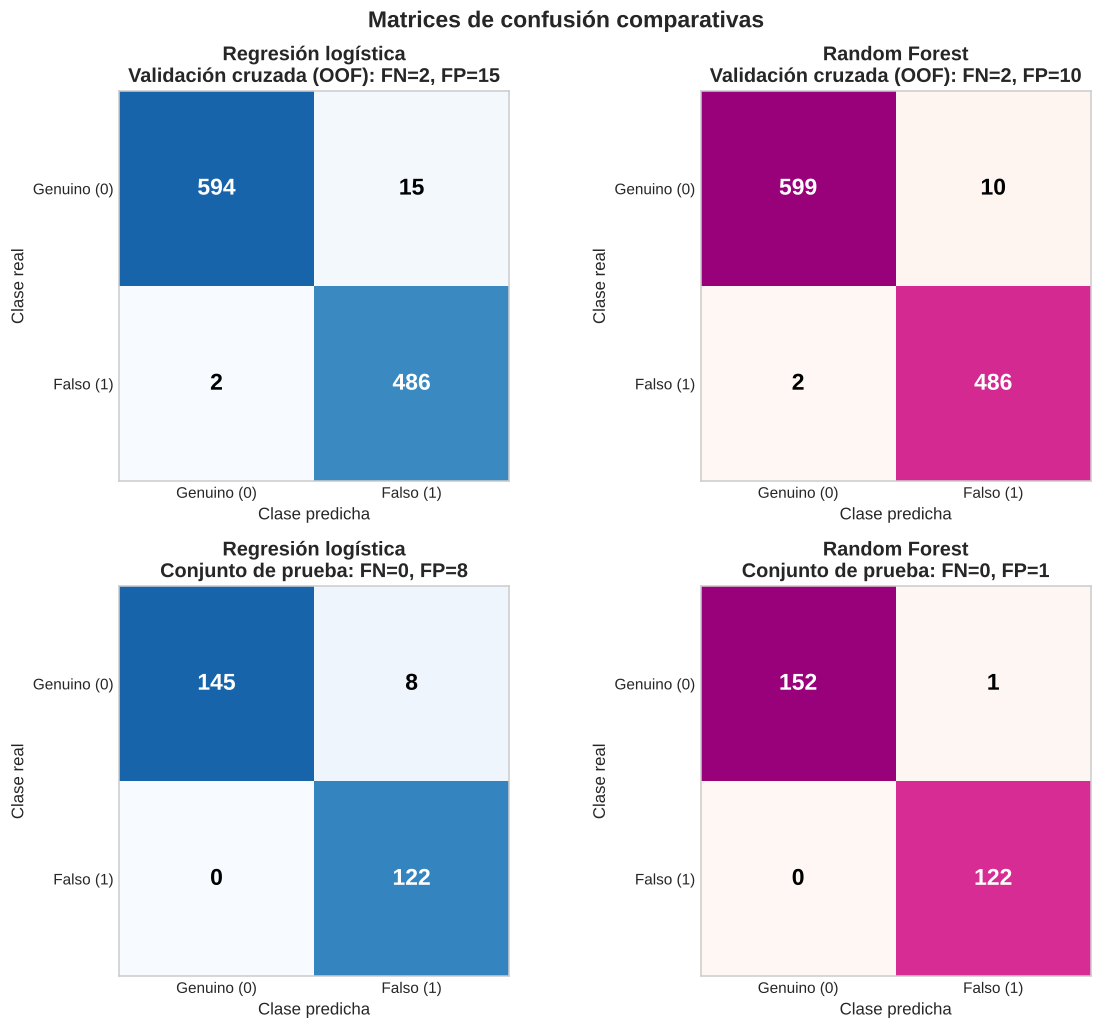

TN  FP  FN   TP
Validación cruzada (OOF) Regresión logística  594  15   2  486
                         Random Forest        599  10   2  486
Prueba                   Regresión logística  145   8   0  122
                         Random Forest        152   1   0  122

In [34]:
def draw_confusion(ax, y_true, y_pred, cmap, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=cm.max() * 1.25)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=15, fontweight='bold',
                    color='white' if cm[i, j] > cm.max() * 0.5 else 'black')
    ax.set_xticks([0, 1], ['Genuino (0)', 'Falso (1)'])
    ax.set_yticks([0, 1], ['Genuino (0)', 'Falso (1)'])
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
    ax.set_title(title)
    ax.grid(False)


fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
panels = [
    (axes[0, 0], oof['y_true'], oof['y_pred_lr'], 'Blues', MODEL_LR, 'Validación cruzada (OOF)'),
    (axes[0, 1], oof['y_true'], oof['y_pred_rf'], 'RdPu', MODEL_RF, 'Validación cruzada (OOF)'),
    (axes[1, 0], y_test, pred_test_lr, 'Blues', MODEL_LR, 'Conjunto de prueba'),
    (axes[1, 1], y_test, pred_test_rf, 'RdPu', MODEL_RF, 'Conjunto de prueba'),
]
for ax, yt, yp, cmap, model, subset in panels:
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    draw_confusion(ax, yt, yp, cmap, f'{model}\n{subset}: FN={fn}, FP={fp}')
fig.suptitle('Matrices de confusión comparativas', fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '11_matrices_confusion_comparativas.png', dpi=300, bbox_inches='tight')
plt.show()

counts = pd.concat({'Validación cruzada (OOF)': cv_metrics[['TN', 'FP', 'FN', 'TP']],
                    'Prueba': test_metrics[['TN', 'FP', 'FN', 'TP']]})
display(counts.astype(int))

# 3.8 Curvas ROC y AUC

Para cada billete, ambos modelos entregan la probabilidad de que sea falso. La curva ROC recorre todos los umbrales posibles; el punto marcado (●) es el umbral de decisión usado en todo el estudio, $\tau = 0.5$. Como ambas curvas quedan muy cerca de la esquina superior izquierda, la fila inferior muestra la misma curva ampliada en esa región.

> En la validación cruzada la curva usa las probabilidades OOF de los cinco pliegues juntas; cada pliegue viene de un modelo distinto, así que es una aproximación agrupada.

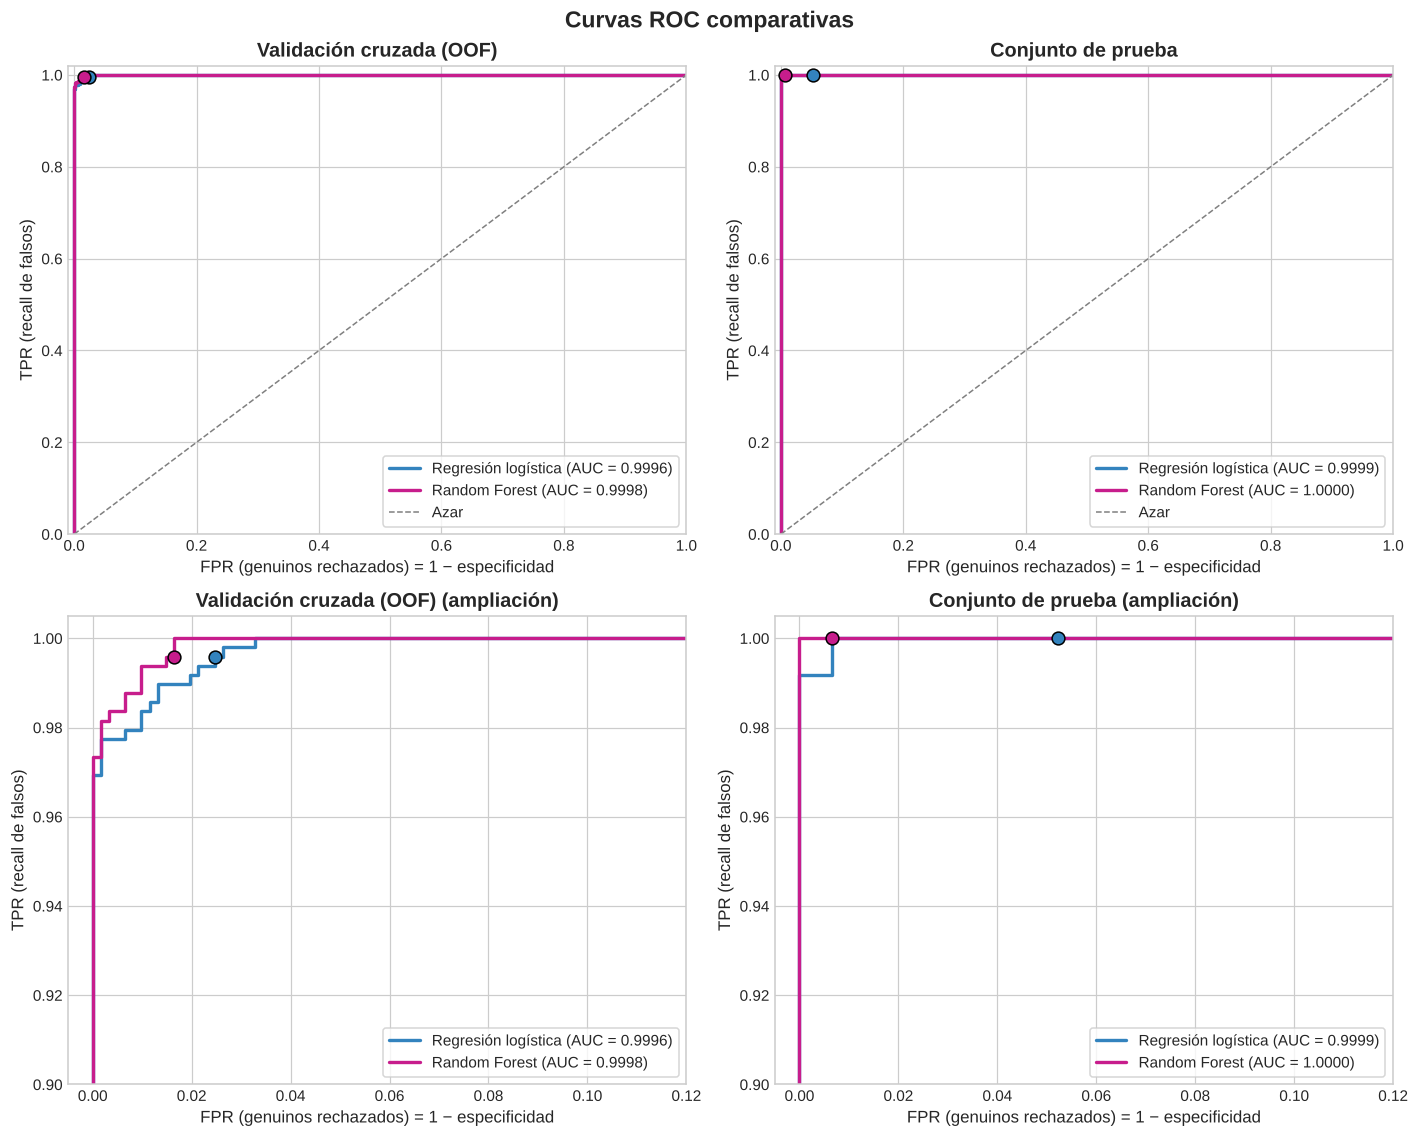

,AUC validación cruzada (OOF),AUC prueba
Regresión logística,0.99960,0.99995
Random Forest,0.99979,1.00000


In [35]:
def roc_panel(ax, y_true, probas, ops, zoom, title):
    for model, proba in probas.items():
        fpr, tpr, _ = roc_curve(y_true, proba)
        auc = roc_auc_score(y_true, proba)
        ax.plot(fpr, tpr, color=MODEL_COLORS[model], linewidth=2.2, label=f'{model} (AUC = {auc:.4f})')
        ax.scatter(*ops[model], s=70, color=MODEL_COLORS[model], edgecolor='black', zorder=5)
    if not zoom:
        ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Azar')
        ax.set_xlim(-0.01, 1.0); ax.set_ylim(0, 1.02)
    else:
        ax.set_xlim(-0.005, 0.12); ax.set_ylim(0.9, 1.005)
        title += ' (ampliación)'
    ax.set_xlabel('FPR (genuinos rechazados) = 1 − especificidad')
    ax.set_ylabel('TPR (recall de falsos)')
    ax.set_title(title)
    ax.legend(loc='lower right', frameon=True)


def operating_point(m):  # (FPR, TPR) con tau = 0.5
    return m['FP'] / (m['FP'] + m['TN']), m['recall_fake']


ops_cv = {MODEL_LR: operating_point(cv_metrics.loc[MODEL_LR]), MODEL_RF: operating_point(cv_metrics.loc[MODEL_RF])}
ops_test = {MODEL_LR: operating_point(test_metrics.loc[MODEL_LR]), MODEL_RF: operating_point(test_metrics.loc[MODEL_RF])}
probas_cv = {MODEL_LR: oof['proba_lr'], MODEL_RF: oof['proba_rf']}
probas_test = {MODEL_LR: proba_test_lr, MODEL_RF: proba_test_rf}

fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
roc_panel(axes[0, 0], oof['y_true'], probas_cv, ops_cv, False, 'Validación cruzada (OOF)')
roc_panel(axes[0, 1], y_test, probas_test, ops_test, False, 'Conjunto de prueba')
roc_panel(axes[1, 0], oof['y_true'], probas_cv, ops_cv, True, 'Validación cruzada (OOF)')
roc_panel(axes[1, 1], y_test, probas_test, ops_test, True, 'Conjunto de prueba')
fig.suptitle('Curvas ROC comparativas', fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '12_curvas_roc_comparativas.png', dpi=300, bbox_inches='tight')
plt.show()

display(pd.DataFrame({
    'AUC validación cruzada (OOF)': cv_metrics['roc_auc'],
    'AUC prueba': test_metrics['roc_auc'],
}).round(5))

# 3.9 Prueba de hipótesis emparejada sobre la métrica principal

Medida de rendimiento: recall de la clase falsa en cada uno de los 5 pliegues. Como ambos modelos se evaluaron en los mismos pliegues, se forman 5 pares y se trabaja con la diferencia $d_i = \text{recall}_{LR,i} - \text{recall}_{RF,i}$.

- $H_0$: $\mu_d = 0$ (el recall esperado de ambos modelos es el mismo).
- $H_1$: $\mu_d \neq 0$ (el recall esperado difiere; prueba bilateral).
- Nivel de significancia: $\alpha = 0.05$.
- Prueba principal: $t$ pareada con la corrección de Nadeau y Bengio (2003), $t = \dfrac{\bar d}{\sqrt{\left(\frac{1}{k} + \frac{n_{prueba}}{n_{entrenamiento}}\right) s_d^2}}$, con $k = 5$ pliegues y $k-1 = 4$ grados de libertad.
- Referencia: $t$ pareada convencional, $t = \dfrac{\bar d}{s_d/\sqrt{k}}$, que se muestra sin corregir y solo para comparar.

### Supuestos y precauciones

1. Pareo: cada par proviene de los mismos billetes de validación (verificado en 3.4).
2. Normalidad de las diferencias: con solo 5 pares la prueba de Shapiro–Wilk tiene muy poca potencia; se reporta como referencia.
3. Independencia: *no se cumple del todo*. Los conjuntos de entrenamiento de los pliegues se traslapan en ~75 %, lo que hace que la varianza de $\bar d$ se subestime y la prueba sea demasiado optimista. Por eso la prueba principal es la $t$ con corrección de Nadeau y Bengio, que reemplaza $1/k$ por $1/k + n_{prueba}/n_{entrenamiento}$ en la varianza. La $t$ convencional no corrige esta dependencia y se muestra solo como referencia. La corrección reduce el optimismo, pero no convierte 5 pliegues en una muestra independiente: la potencia para detectar diferencias pequeñas sigue siendo baja.
4. Resolución: cada pliegue tiene ~97–98 billetes falsos, así que un solo FN mueve el recall en ≈ 0.01.
5. Caso degenerado: si todas las diferencias fueran iguales ($s_d = 0$), el estadístico $t$ no está definido (división entre cero). El código lo contempla: con diferencia media cero reporta $t = 0$ y $p = 1$; con diferencia media distinta de cero reporta $|t| = \infty$ y $p = 0$.

> Cómo leer el resultado: no rechazar $H_0$ no demuestra que los modelos sean equivalentes; solo indica que estos datos no bastan para detectar una diferencia. Para dimensionar qué diferencias son compatibles con los datos se reporta además un intervalo de confianza de 95 % para $\mu_d$.


In [36]:
alpha = 0.05
a = paired['recall_fake_lr'].to_numpy()
b = paired['recall_fake_rf'].to_numpy()
d = a - b
k = len(d)
dfree = k - 1
d_mean, d_sd = d.mean(), d.std(ddof=1)

# Corrección de Nadeau y Bengio: proporción prueba/entrenamiento de cada pliegue externo
ratio = np.mean([len(idx_val) / len(idx_tr) for idx_tr, idx_val in folds])
t_crit = stats.t.ppf(1 - alpha / 2, dfree)


def t_from_se(mean_diff, se, df_):
    # Devuelve (t, p). Si el error estándar es 0 el estadístico no está definido:
    # diferencia media 0 -> t = 0, p = 1; diferencia media distinta de 0 -> |t| = inf, p = 0.
    if se == 0:
        return (0.0, 1.0) if mean_diff == 0 else (float(np.sign(mean_diff) * np.inf), 0.0)
    t = mean_diff / se
    return t, 2 * stats.t.sf(abs(t), df_)


se_std = d_sd / np.sqrt(k)
se_nb = np.sqrt((1 / k + ratio) * d_sd ** 2)
t_std, p_std = t_from_se(d_mean, se_std, dfree)      # referencia (sin corregir)
t_nb, p_nb = t_from_se(d_mean, se_nb, dfree)         # prueba principal
if d_sd > 0:                                         # control cruzado con scipy
    check = stats.ttest_rel(a, b)
    assert np.isclose(t_std, check.statistic) and np.isclose(p_std, check.pvalue)

ci_std = (d_mean - t_crit * se_std, d_mean + t_crit * se_std)
ci_nb = (d_mean - t_crit * se_nb, d_mean + t_crit * se_nb)

sh_w, sh_p = stats.shapiro(d) if d_sd > 0 else (np.nan, np.nan)

tabla_d = pd.DataFrame({'recall_LR': a, 'recall_RF': b, 'd = LR − RF': d},
                       index=pd.RangeIndex(1, k + 1, name='fold'))
display(tabla_d.round(4))

print(f'Diferencia media (LR − RF): {d_mean:+.6f}   desviación estándar de d: {d_sd:.6f}')
print(f'Shapiro–Wilk de las diferencias: W = {sh_w:.4f}, p = {sh_p:.4f}  (n = {k}: potencia muy baja)')
print(f'Prueba principal, t con corrección N–B : t({dfree}) = {t_nb:+.4f}, p = {p_nb:.4f}, IC95 % de μ_d = [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]  (n_prueba/n_entrenamiento = {ratio:.3f})')
print(f'Referencia, t pareado convencional    : t({dfree}) = {t_std:+.4f}, p = {p_std:.4f}, IC95 % de μ_d = [{ci_std[0]:+.4f}, {ci_std[1]:+.4f}]  (no corrige la dependencia entre pliegues)')
decision_nb = 'NO se rechaza H0' if p_nb >= alpha else 'Se rechaza H0'
decision_std = 'NO se rechaza H0' if p_std >= alpha else 'Se rechaza H0'
print(f'Decisión con α = {alpha}: {decision_nb} (prueba principal, N–B) | {decision_std} (referencia, t convencional)')


,recall_LR,recall_RF,d = LR − RF
fold,,,
1,1.0000,1.0000,0.0000
2,0.9898,1.0000,-0.0102
3,1.0000,0.9898,0.0102
4,0.9897,1.0000,-0.0103
5,1.0000,0.9897,0.0103


Diferencia media (LR − RF): +0.000000   desviación estándar de d: 0.010257
Shapiro–Wilk de las diferencias: W = 0.8248, p = 0.1270  (n = 5: potencia muy baja)
Prueba principal, t con corrección N–B : t(4) = +0.0000, p = 1.0000, IC95 % de μ_d = [-0.0191, +0.0191]  (n_prueba/n_entrenamiento = 0.250)
Referencia, t pareado convencional    : t(4) = +0.0000, p = 1.0000, IC95 % de μ_d = [-0.0127, +0.0127]  (no corrige la dependencia entre pliegues)
Decisión con α = 0.05: NO se rechaza H0 (prueba principal, N–B) | NO se rechaza H0 (referencia, t convencional)


### Relevancia práctica frente a significancia estadística

Una diferencia puede ser estadísticamente significativa y casi irrelevante, o al revés. Por eso se traducen las diferencias a billetes: cuántas falsificaciones aceptadas (FN) y cuántos genuinos rechazados (FP) tiene cada modelo en las mismas 1,097 predicciones OOF.

,FN,FP,falsificaciones aceptadas (% de falsos),genuinos rechazados (% de genuinos)
Regresión logística,2,15,0.41,2.46
Random Forest,2,10,0.41,1.64


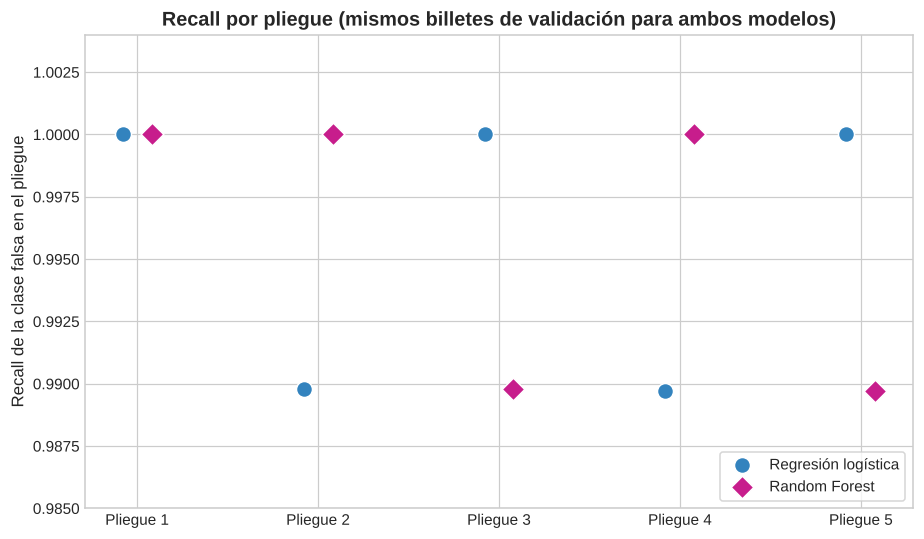

In [37]:
practical = cv_metrics[['FN', 'FP']].astype(int).copy()
practical['falsificaciones aceptadas (% de falsos)'] = (cv_metrics['FN'] / (cv_metrics['FN'] + cv_metrics['TP']) * 100).round(2)
practical['genuinos rechazados (% de genuinos)'] = (cv_metrics['FP'] / (cv_metrics['FP'] + cv_metrics['TN']) * 100).round(2)
display(practical)

fig, ax = plt.subplots(figsize=(8.5, 5))
folds_x = np.arange(1, k + 1)
ax.scatter(folds_x - 0.08, a, s=110, color=MODEL_COLORS[MODEL_LR], edgecolor='white', zorder=3, label=MODEL_LR)
ax.scatter(folds_x + 0.08, b, s=110, color=MODEL_COLORS[MODEL_RF], edgecolor='white', zorder=3, marker='D', label=MODEL_RF)
ax.set_xticks(folds_x, [f'Pliegue {i}' for i in folds_x])
ax.set_ylim(0.985, 1.004)
ax.set_ylabel('Recall de la clase falsa en el pliegue')
ax.set_title('Recall por pliegue (mismos billetes de validación para ambos modelos)')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
fig.savefig(PLOTS_DIR / '13_recall_por_pliegue_pareado.png', dpi=300, bbox_inches='tight')
plt.show()

# 3.10 Billetes mal clasificados: falsos negativos y falsos positivos

Se identifica cada billete mal clasificado, en validación cruzada y en prueba, con su tipo de error, su probabilidad de ser falso y los valores de sus cuatro características. Después se comprueba si los dos modelos fallan en los mismos billetes.

Como el dataset tiene registros con características idénticas, se reportan dos conteos: las filas mal clasificadas y los patrones de características distintos que representan (las filas idénticas cuentan una sola vez).


In [38]:
def collect_errors(frame, y_true_col, pred_col, proba_col, model, subset, has_fold):
    wrong = frame[frame[y_true_col] != frame[pred_col]].copy()
    out = pd.DataFrame({
        'conjunto': subset, 'modelo': model,
        'fold': wrong['fold'].to_numpy() if has_fold else np.nan,
        'index': wrong['index'].to_numpy(),
        'y_true': wrong[y_true_col].to_numpy(), 'y_pred': wrong[pred_col].to_numpy(),
        'proba_fake': wrong[proba_col].to_numpy(),
    })
    out['tipo_error'] = np.where(out['y_true'] == 1, 'FN (falso aceptado)', 'FP (genuino rechazado)')
    return pd.concat([out.reset_index(drop=True),
                      df.loc[out['index'], FEATURES].reset_index(drop=True)], axis=1)


errors = pd.concat([
    collect_errors(oof, 'y_true', 'y_pred_lr', 'proba_lr', MODEL_LR, 'Validación cruzada (OOF)', True),
    collect_errors(oof, 'y_true', 'y_pred_rf', 'proba_rf', MODEL_RF, 'Validación cruzada (OOF)', True),
    collect_errors(test_predictions, 'y_true', 'y_pred_lr', 'proba_lr', MODEL_LR, 'Prueba', False),
    collect_errors(test_predictions, 'y_true', 'y_pred_rf', 'proba_rf', MODEL_RF, 'Prueba', False),
], ignore_index=True)

print('Número de billetes mal clasificados por conjunto, modelo y tipo de error:')
display(errors.groupby(['conjunto', 'modelo', 'tipo_error']).size().unstack(fill_value=0))

# Filas mal clasificadas frente a patrones de características distintos (filas idénticas cuentan una vez)
patron = errors[FEATURES].round(6).astype(str).apply('|'.join, axis=1)
print('Filas mal clasificadas y patrones de características distintos:')
display(errors.assign(patron=patron).groupby(['conjunto', 'modelo', 'tipo_error'])
        .agg(filas=('index', 'size'), patrones_distintos=('patron', 'nunique')))

print('Falsos negativos (falsificaciones aceptadas), que son el error costoso:')
display(errors[errors['tipo_error'].str.startswith('FN')]
        .sort_values(['conjunto', 'modelo', 'index']).round(4).reset_index(drop=True))

Número de billetes mal clasificados por conjunto, modelo y tipo de error:


tipo_error                                    FN (falso aceptado)  \
conjunto                 modelo                                     
Prueba                   Random Forest                          0   
                         Regresión logística                    0   
Validación cruzada (OOF) Random Forest                          2   
                         Regresión logística                    2   

tipo_error                                    FP (genuino rechazado)  
conjunto                 modelo                                       
Prueba                   Random Forest                             1  
                         Regresión logística                       8  
Validación cruzada (OOF) Random Forest                            10  
                         Regresión logística                      15

Filas mal clasificadas y patrones de características distintos:


filas  \
conjunto                 modelo              tipo_error                      
Prueba                   Random Forest       FP (genuino rechazado)      1   
                         Regresión logística FP (genuino rechazado)      8   
Validación cruzada (OOF) Random Forest       FN (falso aceptado)         2   
                                             FP (genuino rechazado)     10   
                         Regresión logística FN (falso aceptado)         2   
                                             FP (genuino rechazado)     15   

                                                                     patrones_distintos  
conjunto                 modelo              tipo_error                                  
Prueba                   Random Forest       FP (genuino rechazado)                   1  
                         Regresión logística FP (genuino rechazado)                   6  
Validación cruzada (OOF) Random Forest       FN (falso aceptado)                      2  
                                             FP (genuino rechazado)                  10  
                         Regresión logística FN (falso aceptado)                      2  
                                             FP (genuino rechazado)                   8

Falsos negativos (falsificaciones aceptadas), que son el error costoso:


,conjunto,modelo,fold,index,y_true,y_pred,proba_fake,tipo_error,variance,skewness,kurtosis,entropy
0,Validación cruzada (OOF),Random Forest,3.0,910,1,0,0.4389,FN (falso aceptado),0.5530,-3.4619,1.7048,1.1008
1,Validación cruzada (OOF),Random Forest,5.0,1075,1,0,0.4950,FN (falso aceptado),0.3764,-0.8236,0.7854,0.7452
2,Validación cruzada (OOF),Regresión logística,4.0,918,1,0,0.3672,FN (falso aceptado),2.3917,4.5565,-4.9888,-2.8987
3,Validación cruzada (OOF),Regresión logística,2.0,1101,1,0,0.4359,FN (falso aceptado),2.1943,4.5503,-4.9760,-2.7254


In [39]:
# ¿Fallan los dos modelos en los mismos billetes? (validación cruzada)
cv_err = errors[errors['conjunto'] == 'Validación cruzada (OOF)']
rows = []
for tipo in ['FN (falso aceptado)', 'FP (genuino rechazado)']:
    s_lr = set(cv_err[(cv_err['modelo'] == MODEL_LR) & (cv_err['tipo_error'] == tipo)]['index'])
    s_rf = set(cv_err[(cv_err['modelo'] == MODEL_RF) & (cv_err['tipo_error'] == tipo)]['index'])
    rows.append({'tipo de error': tipo, 'solo regresión logística': len(s_lr - s_rf),
                 'solo Random Forest': len(s_rf - s_lr), 'ambos modelos': len(s_lr & s_rf)})
overlap = pd.DataFrame(rows).set_index('tipo de error')
print('Billetes mal clasificados en validación cruzada (OOF), según qué modelo falla:')
display(overlap)

print('Billetes de prueba mal clasificados:')
test_err = errors[errors['conjunto'] == 'Prueba'].sort_values(['modelo', 'index']).round(4)
display(test_err.reset_index(drop=True) if len(test_err) else 'Ninguno')

Billetes mal clasificados en validación cruzada (OOF), según qué modelo falla:


,solo regresión logística,solo Random Forest,ambos modelos
tipo de error,,,
FN (falso aceptado),2,2,0
FP (genuino rechazado),15,10,0


Billetes de prueba mal clasificados:


,conjunto,modelo,fold,index,y_true,y_pred,proba_fake,tipo_error,variance,skewness,kurtosis,entropy
0,Prueba,Random Forest,NaN,95,0,1,0.7133,FP (genuino rechazado),-0.6447,-4.6062,8.3470,-2.7099
1,Prueba,Regresión logística,NaN,4,0,1,0.6911,FP (genuino rechazado),0.3292,-4.4552,4.5718,-0.9888
2,Prueba,Regresión logística,NaN,21,0,1,0.6911,FP (genuino rechazado),0.3292,-4.4552,4.5718,-0.9888
3,Prueba,Regresión logística,NaN,170,0,1,0.5541,FP (genuino rechazado),0.5706,-0.0248,1.2421,-0.5621
4,Prueba,Regresión logística,NaN,315,0,1,0.6911,FP (genuino rechazado),0.3292,-4.4552,4.5718,-0.9888
5,Prueba,Regresión logística,NaN,345,0,1,0.6338,FP (genuino rechazado),-1.8584,7.8860,-1.6643,-1.8384
6,Prueba,Regresión logística,NaN,476,0,1,0.6075,FP (genuino rechazado),0.3798,0.7098,0.7572,-0.4444
7,Prueba,Regresión logística,NaN,498,0,1,0.5541,FP (genuino rechazado),0.5706,-0.0248,1.2421,-0.5621
8,Prueba,Regresión logística,NaN,716,0,1,0.7349,FP (genuino rechazado),0.5195,-3.2633,3.0895,-0.9849


# 3.11 Efecto de los registros duplicados

El dataset tiene 24 filas duplicadas (idénticas en las cuatro características y en la clase). Se conservaron en el análisis principal (sección 1.4); aquí se mide su efecto y se reporta, sin eliminar nada.

El riesgo es que una fila quede en la validación de un pliegue y un registro idéntico esté en el entrenamiento de ese mismo pliegue: el modelo ya habría visto un registro con exactamente las mismas características y la estimación podría ser optimista. Dos filas con las mismas cuatro características y la misma clase no demuestran que sean el mismo billete físico; solo que son indistinguibles para el modelo. Aquí se cuenta cuántas filas están en esa situación y se recalculan las métricas OOF sin ellas; lo mismo se hace con las filas de `X_test` que tienen copia exacta en `X_train` (solo como análisis de sensibilidad; las tablas principales no cambian).

In [40]:
dup_mask_all = df.duplicated(keep=False)
dup_id = df.groupby(FEATURES + [TARGET]).ngroup()           # mismo id = filas idénticas

print(f'Filas duplicadas (según df.duplicated): {df.duplicated().sum()} | '
      f'filas que pertenecen a algún grupo repetido: {dup_mask_all.sum()} en {dup_id[dup_mask_all].nunique()} grupos')
print('Clase de las filas en grupos repetidos:', df.loc[dup_mask_all, TARGET].map(CLASS_LABELS).value_counts().to_dict())

# Filas de validación cuya copia exacta está en el entrenamiento de su pliegue
leaky_rows = []
for fold, (idx_tr, idx_val) in enumerate(folds, start=1):
    train_ids = set(dup_id.loc[X_train.index[idx_tr]])
    for lab in X_train.index[idx_val]:
        if dup_id.loc[lab] in train_ids:
            leaky_rows.append((fold, lab))
leaky = pd.DataFrame(leaky_rows, columns=['fold', 'index'])
oof['copia_en_entrenamiento'] = oof.set_index(['fold', 'index']).index.isin(leaky.set_index(['fold', 'index']).index)

test_dup_in_train = int(dup_id.loc[X_test.index].isin(set(dup_id.loc[X_train.index])).sum())
test_predictions['copia_en_entrenamiento'] = dup_id.loc[X_test.index].isin(set(dup_id.loc[X_train.index])).to_numpy()
print(f'Filas de validación con copia exacta en el entrenamiento de su pliegue: {len(leaky)} de {len(oof)}')
print(f'Filas de X_test con copia exacta en X_train: {test_dup_in_train} de {len(X_test)}')


def pooled(sub, suffix):
    yt, yp = sub['y_true'], sub[f'y_pred_{suffix}']
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    return {'n': len(sub), 'recall_fake': tp / (tp + fn), 'precision_fake': tp / (tp + fp),
            'f1_fake': f1_score(yt, yp), 'accuracy': accuracy_score(yt, yp),
            'specificity': tn / (tn + fp), 'FN': fn, 'FP': fp}


sens_rows = {}
for label, sub in [('Todas las filas', oof), ('Sin filas con copia en el entrenamiento', oof[~oof['copia_en_entrenamiento']])]:
    for model, suffix in [(MODEL_LR, 'lr'), (MODEL_RF, 'rf')]:
        sens_rows[(label, model)] = pooled(sub, suffix)
sensitivity = pd.DataFrame(sens_rows).T
sensitivity.index.names = ['conjunto de filas', 'modelo']
display(sensitivity.round(4))

wrong_with_copy = oof[oof['copia_en_entrenamiento'] & ((oof['y_true'] != oof['y_pred_lr']) | (oof['y_true'] != oof['y_pred_rf']))]
print(f'Billetes mal clasificados (por al menos un modelo) que tenían copia en el entrenamiento: {len(wrong_with_copy)}')

# Efecto en el conjunto de prueba: métricas sin las filas de X_test que tienen copia exacta en X_train
test_sens = {}
for label, mask in [('Todas las filas de X_test', np.ones(len(test_predictions), dtype=bool)),
                    ('Sin filas con copia en X_train', ~test_predictions['copia_en_entrenamiento'].to_numpy())]:
    sub = test_predictions[mask]
    for model, suffix in [(MODEL_LR, 'lr'), (MODEL_RF, 'rf')]:
        test_sens[(label, model)] = pooled(sub, suffix)
test_sensitivity = pd.DataFrame(test_sens).T
test_sensitivity.index.names = ['conjunto de filas', 'modelo']
print('Conjunto de prueba, con y sin las filas que tienen copia exacta en X_train:')
display(test_sensitivity.round(4))

# Marca, en la tabla de errores, qué billetes tenían copia exacta en el entrenamiento
leaky_keys = set(map(tuple, leaky[['fold', 'index']].to_numpy()))
test_flag = dict(zip(test_predictions['index'], test_predictions['copia_en_entrenamiento']))
errors['copia_en_entrenamiento'] = [
    test_flag[r['index']] if r['conjunto'] == 'Prueba' else (int(r['fold']), int(r['index'])) in leaky_keys
    for _, r in errors.iterrows()
]
print('Billetes mal clasificados que tenían copia exacta en el entrenamiento:')
display(errors.groupby(['conjunto', 'modelo', 'tipo_error'])['copia_en_entrenamiento']
        .agg(['sum', 'count']).rename(columns={'sum': 'con copia', 'count': 'total'}))

Filas duplicadas (según df.duplicated): 24 | filas que pertenecen a algún grupo repetido: 35 en 11 grupos
Clase de las filas en grupos repetidos: {'Genuino (0)': 35}
Filas de validación con copia exacta en el entrenamiento de su pliegue: 23 de 1097
Filas de X_test con copia exacta en X_train: 9 de 275


n  \
conjunto de filas                       modelo                        
Todas las filas                         Regresión logística  1097.0   
                                        Random Forest        1097.0   
Sin filas con copia en el entrenamiento Regresión logística  1074.0   
                                        Random Forest        1074.0   

                                                             recall_fake  \
conjunto de filas                       modelo                             
Todas las filas                         Regresión logística       0.9959   
                                        Random Forest             0.9959   
Sin filas con copia en el entrenamiento Regresión logística       0.9959   
                                        Random Forest             0.9959   

                                                             precision_fake  \
conjunto de filas                       modelo                                
Todas las filas                         Regresión logística          0.9701   
                                        Random Forest                0.9798   
Sin filas con copia en el entrenamiento Regresión logística          0.9898   
                                        Random Forest                0.9798   

                                                             f1_fake  \
conjunto de filas                       modelo                         
Todas las filas                         Regresión logística   0.9828   
                                        Random Forest         0.9878   
Sin filas con copia en el entrenamiento Regresión logística   0.9928   
                                        Random Forest         0.9878   

                                                             accuracy  \
conjunto de filas                       modelo                          
Todas las filas                         Regresión logística    0.9845   
                                        Random Forest          0.9891   
Sin filas con copia en el entrenamiento Regresión logística    0.9935   
                                        Random Forest          0.9888   

                                                             specificity   FN  \
conjunto de filas                       modelo                                  
Todas las filas                         Regresión logística       0.9754  2.0   
                                        Random Forest             0.9836  2.0   
Sin filas con copia en el entrenamiento Regresión logística       0.9915  2.0   
                                        Random Forest             0.9829  2.0   

                                                               FP  
conjunto de filas                       modelo                     
Todas las filas                         Regresión logística  15.0  
                                        Random Forest        10.0  
Sin filas con copia en el entrenamiento Regresión logística   5.0  
                                        Random Forest        10.0

Billetes mal clasificados (por al menos un modelo) que tenían copia en el entrenamiento: 10
Conjunto de prueba, con y sin las filas que tienen copia exacta en X_train:


n  recall_fake  \
conjunto de filas              modelo                                    
Todas las filas de X_test      Regresión logística  275.0          1.0   
                               Random Forest        275.0          1.0   
Sin filas con copia en X_train Regresión logística  266.0          1.0   
                               Random Forest        266.0          1.0   

                                                    precision_fake  f1_fake  \
conjunto de filas              modelo                                         
Todas las filas de X_test      Regresión logística          0.9385   0.9683   
                               Random Forest                0.9919   0.9959   
Sin filas con copia en X_train Regresión logística          0.9919   0.9959   
                               Random Forest                0.9919   0.9959   

                                                    accuracy  specificity  \
conjunto de filas              modelo                                       
Todas las filas de X_test      Regresión logística    0.9709       0.9477   
                               Random Forest          0.9964       0.9935   
Sin filas con copia en X_train Regresión logística    0.9962       0.9931   
                               Random Forest          0.9962       0.9931   

                                                     FN   FP  
conjunto de filas              modelo                         
Todas las filas de X_test      Regresión logística  0.0  8.0  
                               Random Forest        0.0  1.0  
Sin filas con copia en X_train Regresión logística  0.0  1.0  
                               Random Forest        0.0  1.0

Billetes mal clasificados que tenían copia exacta en el entrenamiento:


con copia  \
conjunto                 modelo              tipo_error                          
Prueba                   Random Forest       FP (genuino rechazado)          0   
                         Regresión logística FP (genuino rechazado)          7   
Validación cruzada (OOF) Random Forest       FN (falso aceptado)             0   
                                             FP (genuino rechazado)          0   
                         Regresión logística FN (falso aceptado)             0   
                                             FP (genuino rechazado)         10   

                                                                     total  
conjunto                 modelo              tipo_error                     
Prueba                   Random Forest       FP (genuino rechazado)      1  
                         Regresión logística FP (genuino rechazado)      8  
Validación cruzada (OOF) Random Forest       FN (falso aceptado)         2  
                                             FP (genuino rechazado)     10  
                         Regresión logística FN (falso aceptado)         2  
                                             FP (genuino rechazado)     15

# 3.12 Exportación de resultados de la comparación

Se guardan en `../results/comparacion/` los archivos que respaldan las tablas y figuras del artículo. Las figuras ya quedaron en `../report/plots/` (`11_` a `13_`).

| Archivo | Contenido |
|---|---|
| `01_mediciones_por_pliegue.csv` | Métricas por pliegue de ambos modelos, con especificidad, AUC y conteos TN/FP/FN/TP (incluye las columnas que consume la prueba estadística) |
| `02_predicciones_fuera_de_muestra.csv` | Predicción y probabilidad OOF de cada billete de `X_train`, para ambos modelos |
| `03_metricas_cv_y_prueba.csv` | Métricas principal y complementarias, con conteos TN/FP/FN/TP, en validación cruzada y en prueba |
| `04_prueba_estadistica.txt` | Hipótesis, α, supuestos, estadísticos, p-valores e intervalos |
| `05_predicciones_prueba.csv` | Predicción y probabilidad de cada billete de `X_test` |
| `06_billetes_mal_clasificados.csv` | Cada billete mal clasificado, con tipo de error y características |
| `07_sensibilidad_duplicados.csv` | Métricas OOF y de prueba con y sin las filas que tienen copia exacta en el entrenamiento |
| `08_versiones_software.txt` | Versiones de software y semilla |
| `09_resumen_por_pliegue.csv` | Tabla principal: media ± desviación estándar por pliegue de cada métrica, para ambos modelos |

In [41]:
folds_full.to_csv(RESULTS_DIR / '01_mediciones_por_pliegue.csv')
summary_cv.to_csv(RESULTS_DIR / '09_resumen_por_pliegue.csv')
oof.to_csv(RESULTS_DIR / '02_predicciones_fuera_de_muestra.csv', index=False)

metrics_export = pd.concat({'Validación cruzada (OOF)': cv_metrics, 'Prueba': test_metrics}, names=['conjunto', 'modelo'])
metrics_export.to_csv(RESULTS_DIR / '03_metricas_cv_y_prueba.csv')

report = f'''PRUEBA DE HIPÓTESIS EMPAREJADA: recall de la clase falsa (clase 1), 5 pliegues
{'=' * 78}
Medida: recall de falsos por pliegue; diferencia d_i = recall_LR,i - recall_RF,i (pliegues idénticos para ambos modelos)
H0: mu_d = 0 (el recall esperado de ambos modelos es el mismo)
H1: mu_d != 0 (prueba bilateral)
alpha = {alpha}

Recall por pliegue  LR: {np.round(a, 4).tolist()}
Recall por pliegue  RF: {np.round(b, 4).tolist()}
Diferencias d_i       : {np.round(d, 4).tolist()}
Diferencia media      : {d_mean:+.6f}   (desv. est. de d = {d_sd:.6f}, k = {k})

Supuestos: pareo (verificado); normalidad de d -> Shapiro-Wilk W = {sh_w:.4f}, p = {sh_p:.4f} (n = 5, potencia muy baja);
independencia entre pliegues: no se cumple del todo (entrenamientos traslapados) -> la prueba principal es la t con corrección de Nadeau y Bengio; la t convencional se reporta solo como referencia.

PRUEBA PRINCIPAL - t corregido (N-B): t({dfree}) = {t_nb:+.4f}, p = {p_nb:.4f}, IC95% de mu_d = [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]  (n_prueba/n_entrenamiento = {ratio:.3f})
Referencia - t pareado convencional (no corrige la dependencia entre pliegues): t({dfree}) = {t_std:+.4f}, p = {p_std:.4f}, IC95% de mu_d = [{ci_std[0]:+.4f}, {ci_std[1]:+.4f}]
Decisión (alpha = {alpha}): {decision_nb} (prueba principal); {decision_std} (referencia)

Interpretación: no rechazar H0 no demuestra equivalencia; solo indica que estos datos no permiten detectar una diferencia en el recall.
Billetes (validación cruzada, 1,097 predicciones): LR FN = {int(cv_metrics.loc[MODEL_LR, 'FN'])}, FP = {int(cv_metrics.loc[MODEL_LR, 'FP'])}; RF FN = {int(cv_metrics.loc[MODEL_RF, 'FN'])}, FP = {int(cv_metrics.loc[MODEL_RF, 'FP'])}.
'''
(RESULTS_DIR / '04_prueba_estadistica.txt').write_text(report, encoding='utf-8')

test_predictions.to_csv(RESULTS_DIR / '05_predicciones_prueba.csv', index=False)
errors.to_csv(RESULTS_DIR / '06_billetes_mal_clasificados.csv', index=False)
pd.concat({'Validación cruzada (OOF)': sensitivity, 'Prueba': test_sensitivity}, names=['conjunto']).to_csv(
    RESULTS_DIR / '07_sensibilidad_duplicados.csv')
(RESULTS_DIR / '08_versiones_software.txt').write_text(
    '\n'.join(f'{k}: {v}' for k, v in versions.items()) + f'\nrandom_state: {RANDOM_STATE}\n', encoding='utf-8')

print('Archivos guardados en', RESULTS_DIR.resolve())
for p in sorted(RESULTS_DIR.iterdir()):
    print(' -', p.name)

Archivos guardados en proyecto/results/comparacion
 - 01_mediciones_por_pliegue.csv
 - 02_predicciones_fuera_de_muestra.csv
 - 03_metricas_cv_y_prueba.csv
 - 04_prueba_estadistica.txt
 - 05_predicciones_prueba.csv
 - 06_billetes_mal_clasificados.csv
 - 07_sensibilidad_duplicados.csv
 - 08_versiones_software.txt
 - 09_resumen_por_pliegue.csv


# 3.13 Resumen de resultados

Resumen generado automáticamente a partir de las tablas anteriores (no contiene cifras escritas a mano).

In [42]:
def line(model, m):
    return (f"  {model:<20} recall={m['recall_fake']:.4f}  precision={m['precision_fake']:.4f}  F1={m['f1_fake']:.4f}  "
            f"especificidad={m['specificity']:.4f}  AUC={m['roc_auc']:.5f}  FN={int(m['FN'])}  FP={int(m['FP'])}")

print('Validación cruzada, media ± desviación estándar por pliegue (tabla principal):')
for m in FULL_METRICS:
    print(f"  {m:<15} {MODEL_LR}: {summary_cv.loc[m, MODEL_LR]}   |   {MODEL_RF}: {summary_cv.loc[m, MODEL_RF]}")
print('\nValidación cruzada (OOF agrupado, 1,097 billetes; para matrices, ROC y errores):')
for model in (MODEL_LR, MODEL_RF):
    print(line(model, cv_metrics.loc[model]))
print(f'\nConjunto de prueba ({len(X_test)} billetes, evaluado una sola vez):')
for model in (MODEL_LR, MODEL_RF):
    print(line(model, test_metrics.loc[model]))
print(f'\nPrueba sobre el recall por pliegue (LR − RF): diferencia media = {d_mean:+.6f}')
print(f'  Prueba principal (t con corrección N–B): t({dfree}) = {t_nb:+.4f}, p = {p_nb:.4f}')
print(f'  IC95 % (corregido) de la diferencia: [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]')
print(f'  Referencia (t pareado convencional)  : t({dfree}) = {t_std:+.4f}, p = {p_std:.4f}')
print(f'\nDuplicados: {len(leaky)} filas de validación tenían copia exacta en el entrenamiento de su pliegue.')
for model in (MODEL_LR, MODEL_RF):
    m = sensitivity.loc[('Sin filas con copia en el entrenamiento', model)]
    print(f"  OOF sin esas filas, {model:<20} FN={int(m['FN'])}  FP={int(m['FP'])}  precision={m['precision_fake']:.4f}")
for model in (MODEL_LR, MODEL_RF):
    m = test_sensitivity.loc[('Sin filas con copia en X_train', model)]
    print(f"  Prueba sin filas con copia en X_train, {model:<20} FN={int(m['FN'])}  FP={int(m['FP'])}  n={int(m['n'])}")

Validación cruzada, media ± desviación estándar por pliegue (tabla principal):
  recall_fake     Regresión logística: 0.9959 ± 0.0056   |   Random Forest: 0.9959 ± 0.0056
  precision_fake  Regresión logística: 0.9703 ± 0.0153   |   Random Forest: 0.9801 ± 0.0209
  f1_fake         Regresión logística: 0.9829 ± 0.0084   |   Random Forest: 0.9879 ± 0.0131
  accuracy        Regresión logística: 0.9845 ± 0.0076   |   Random Forest: 0.9890 ± 0.0119
  specificity     Regresión logística: 0.9754 ± 0.0130   |   Random Forest: 0.9835 ± 0.0175
  roc_auc         Regresión logística: 0.9997 ± 0.0002   |   Random Forest: 0.9998 ± 0.0002

Validación cruzada (OOF agrupado, 1,097 billetes; para matrices, ROC y errores):
  Regresión logística  recall=0.9959  precision=0.9701  F1=0.9828  especificidad=0.9754  AUC=0.99960  FN=2  FP=15
  Random Forest        recall=0.9959  precision=0.9798  F1=0.9878  especificidad=0.9836  AUC=0.99979  FN=2  FP=10

Conjunto de prueba (275 billetes, evaluado una sola vez):


# 3.14 Conclusiones de la comparación

El texto de esta celda se genera con las cifras calculadas en las secciones 3.5 a 3.11, para no tener números escritos a mano. Antes de mostrarlo se comprueban los supuestos en los que se apoya la redacción (por ejemplo, que el Random Forest no falle en filas con copia); si alguno deja de cumplirse, la celda se detiene para revisar el texto. Las métricas por pliegue se reportan como media ± desviación estándar de los cinco pliegues y las predicciones agrupadas (1,097 fuera de muestra) se usan para los conteos de errores.

In [43]:
from IPython.display import Markdown, display

# Cifras que se usan en el texto
LR, RF = MODEL_LR, MODEL_RF
CV, TE = 'Validación cruzada (OOF)', 'Prueba'
FN_T, FP_T = 'FN (falso aceptado)', 'FP (genuino rechazado)'


def ms(frame, col):
    return f'{frame[col].mean():.4f} ± {frame[col].std(ddof=1):.4f}'


n_fake_cv = int(cv_metrics.loc[LR, 'FN'] + cv_metrics.loc[LR, 'TP'])
n_fake_te = int(test_metrics.loc[LR, 'FN'] + test_metrics.loc[LR, 'TP'])
fn_cv = {m: int(cv_metrics.loc[m, 'FN']) for m in (LR, RF)}
fp_cv = {m: int(cv_metrics.loc[m, 'FP']) for m in (LR, RF)}
fn_te = {m: int(test_metrics.loc[m, 'FN']) for m in (LR, RF)}
fp_te = {m: int(test_metrics.loc[m, 'FP']) for m in (LR, RF)}

fn_cv_rows = errors[(errors['conjunto'] == CV) & (errors['tipo_error'] == FN_T)]
p_min, p_max = fn_cv_rows['proba_fake'].min(), fn_cv_rows['proba_fake'].max()

# Duplicados
n_dup_rows = int(dup_mask_all.sum())
n_dup_groups = int(dup_id[dup_mask_all].nunique())
dup_only_genuine = set(df.loc[dup_mask_all, TARGET]) == {0}
copy_flag = errors['copia_en_entrenamiento'].astype(bool)


def fp_with_copy(subset, model):
    sel = (errors['conjunto'] == subset) & (errors['modelo'] == model) & (errors['tipo_error'] == FP_T)
    return int(copy_flag[sel].sum())


copy_cv = {m: fp_with_copy(CV, m) for m in (LR, RF)}
copy_te = {m: fp_with_copy(TE, m) for m in (LR, RF)}
ALL_CV, NOCOPY_CV = 'Todas las filas', 'Sin filas con copia en el entrenamiento'
ALL_TE, NOCOPY_TE = 'Todas las filas de X_test', 'Sin filas con copia en X_train'
fp_cv_sin = {m: int(sensitivity.loc[(NOCOPY_CV, m), 'FP']) for m in (LR, RF)}
fp_te_sin = {m: int(test_sensitivity.loc[(NOCOPY_TE, m), 'FP']) for m in (LR, RF)}

pat = errors[FEATURES].round(6).astype(str).apply('|'.join, axis=1)
lr_fp = errors[(errors['modelo'] == LR) & (errors['tipo_error'] == FP_T)]
pat_cv = pat[lr_fp[lr_fp['conjunto'] == CV].index].nunique()
pat_te = pat[lr_fp[lr_fp['conjunto'] == TE].index].nunique()

# Supuestos de la redacción: si alguno falla, hay que revisar el texto
supuestos = {
    'mismo recall por pliegue en ambos modelos': ms(fold_lr_full, 'recall_fake') == ms(fold_rf_full, 'recall_fake'),
    'mismo número de FN en validación': fn_cv[LR] == fn_cv[RF],
    'ningún FN en prueba': fn_te[LR] == fn_te[RF] == 0,
    'ningún billete es FN en ambos modelos': int(overlap.loc[FN_T, 'ambos modelos']) == 0,
    'no se rechaza H0 con N-B ni con la t convencional': p_nb >= alpha and p_std >= alpha,
    'RF con menos FP que LR en el análisis original': fp_cv[RF] < fp_cv[LR] and fp_te[RF] < fp_te[LR],
    'duplicados solo de la clase genuina': dup_only_genuine,
    'RF no falla en filas con copia': copy_cv[RF] == 0 and copy_te[RF] == 0,
    'FP del RF iguales con y sin filas con copia': fp_cv_sin[RF] == fp_cv[RF] and fp_te_sin[RF] == fp_te[RF],
    'LR baja sus FP al quitar filas con copia': fp_cv_sin[LR] < fp_cv[LR] and fp_te_sin[LR] < fp_te[LR],
    'sin copias, LR no tiene más FP que RF': fp_cv_sin[LR] <= fp_cv_sin[RF] and fp_te_sin[LR] <= fp_te_sin[RF],
    'RF con min_samples_leaf=1 en todos los pliegues y en el modelo final':
        set(rf_folds['best_min_samples_leaf']) == {1} and rf_params['min_samples_leaf'] == 1,
    'precisión y F1 por pliegue: diferencia menor que la desviación estándar':
        abs(fold_rf_full['precision_fake'].mean() - fold_lr_full['precision_fake'].mean())
        < max(fold_lr_full['precision_fake'].std(ddof=1), fold_rf_full['precision_fake'].std(ddof=1))
        and abs(fold_rf_full['f1_fake'].mean() - fold_lr_full['f1_fake'].mean())
        < max(fold_lr_full['f1_fake'].std(ddof=1), fold_rf_full['f1_fake'].std(ddof=1)),
}
fallidos = [k for k, ok in supuestos.items() if not ok]
assert not fallidos, f'La redacción de 3.14 ya no coincide con los resultados. Revisar: {fallidos}'

# Texto de las conclusiones
ci_max = max(abs(ci_nb[0]), abs(ci_nb[1])) * 100
texto = f"""
## Detección de falsificaciones (métrica principal)

Ambos modelos alcanzaron un recall muy cercano a uno: {ms(fold_lr_full, 'recall_fake')} en validación cruzada (media ± desviación estándar de los cinco pliegues). En las predicciones agrupadas cada uno aceptó {fn_cv[LR]} falsificaciones de {n_fake_cv} (FN = {fn_cv[LR]}), y en el conjunto de prueba ninguno aceptó alguna (FN = 0 de {n_fake_te}). Los {len(fn_cv_rows)} FN de validación corresponden a billetes distintos, con probabilidades estimadas de ser falso entre {p_min:.3f} y {p_max:.3f}, es decir, cercanas al umbral de decisión. Tener la misma cantidad de errores no implica cometer los mismos errores. El AUC por pliegue fue {ms(fold_lr_full, 'roc_auc')} (regresión logística) y {ms(fold_rf_full, 'roc_auc')} (Random Forest): ambos separan casi perfectamente las dos clases.

## Comparación estadística

La diferencia media de recall entre los modelos fue {d_mean:+.4f}. Con la prueba principal (t pareada con corrección de Nadeau y Bengio) se obtuvo t({dfree}) = {t_nb:.4f} y p = {p_nb:.4f}, con un IC95 % de la diferencia de [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]. La t pareada convencional, mostrada como referencia, lleva a la misma decisión. No se rechaza $H_0$: no hay evidencia de que un modelo detecte más falsificaciones que el otro. Esto no demuestra que sean equivalentes: con cinco pares, el intervalo todavía admite diferencias de hasta {ci_max:.1f} puntos porcentuales en cualquier sentido, y la corrección de Nadeau y Bengio reduce el optimismo de la prueba pero no convierte cinco pliegues en una muestra independiente.

## Billetes genuinos rechazados y registros repetidos

Con todas las filas, el Random Forest rechazó menos billetes genuinos: {fp_cv[RF]} frente a {fp_cv[LR]} FP en validación y {fp_te[RF]} frente a {fp_te[LR]} en prueba (especificidad por pliegue de {ms(fold_rf_full, 'specificity')} frente a {ms(fold_lr_full, 'specificity')}). Esa diferencia hay que leerla junto con los registros repetidos. El dataset tiene {n_dup_rows} filas repartidas en {n_dup_groups} grupos de registros idénticos, todas de la clase genuina. De las {len(oof):,} filas de validación, {len(leaky)} tenían un registro idéntico en el entrenamiento de su pliegue; de las {len(X_test)} filas de prueba, {test_dup_in_train} lo tenían en `X_train`.

La regresión logística cometió {copy_cv[LR]} de sus {fp_cv[LR]} FP de validación y {copy_te[LR]} de sus {fp_te[LR]} FP de prueba sobre filas con copia en el entrenamiento. El Random Forest no cometió ninguno de los suyos sobre ese tipo de filas, de modo que sus FP no dependen de los duplicados: tiene {fp_cv_sin[RF]} FP en validación con y sin esas filas, y {fp_te_sin[RF]} en prueba con y sin ellas. Lo que cambia es la regresión logística, que al excluirlas baja de {fp_cv[LR]} a {fp_cv_sin[LR]} FP en validación y de {fp_te[LR]} a {fp_te_sin[LR]} en prueba.

Entonces, la desventaja aparente de la regresión logística en FP se concentra en filas con registro idéntico en el entrenamiento; sin ellas, la diferencia desaparece (prueba) o se invierte (validación cruzada). Esta comparación es descriptiva y no se contrastó estadísticamente.

Una hipótesis, que este análisis no prueba, es que el Random Forest, al no estar podado (`min_samples_leaf=1` en todos los pliegues y en el modelo final), clasifica bien esas filas porque ya vio un registro idéntico en el entrenamiento, mientras que la regresión logística, con una frontera lineal, vuelve a equivocarse en ellas. Comprobarla exigiría una validación cruzada agrupada por registro idéntico. Además, esos registros son indistinguibles para el modelo, pero no se afirma que correspondan al mismo billete físico, y las filas mal clasificadas no son errores independientes: los {fp_te[LR]} FP de la regresión logística en prueba corresponden a {pat_te} patrones de características distintos, y los {fp_cv[LR]} de validación a {pat_cv}.

## Respuesta a la pregunta de investigación

En la métrica principal, el recall de la clase falsa, no hay diferencia distinguible entre los modelos: ambos detectan casi todas las falsificaciones y la diferencia no es estadísticamente distinguible de cero. En precisión y F1 por pliegue el Random Forest sale algo mejor (precisión {ms(fold_rf_full, 'precision_fake')} frente a {ms(fold_lr_full, 'precision_fake')}; F1 {ms(fold_rf_full, 'f1_fake')} frente a {ms(fold_lr_full, 'f1_fake')}), pero esas diferencias quedan dentro de la desviación estándar entre pliegues. Las diferencias en FP no son concluyentes: dependen de cómo se reparten los registros repetidos entre entrenamiento y validación y no se contrastaron con una prueba estadística. Por tanto, con este experimento no se puede declarar que un modelo identifique mejor los billetes falsos que el otro; si hubiera que elegir, la decisión tendría que apoyarse en criterios que aquí no se evaluaron, como la interpretabilidad o el costo de cómputo.

## Limitaciones

- Una sola semilla y una sola partición 80/20; los resultados de prueba dependen de qué billetes quedaron en `X_test` ({len(X_test)} billetes, {n_fake_te} falsos).
- La comparación estadística usa solo cinco pares de diferencias y tiene baja potencia para detectar diferencias pequeñas.
- La validación cruzada no es agrupada: registros idénticos pudieron quedar en entrenamiento y validación. La validación por grupos de registros idénticos (`StratifiedGroupKFold`) es una mejora posible, pero exigiría volver a ejecutar ambos modelos con el mismo esquema.
- Los FN se ubicaron cerca del umbral 0.5. Un umbral guiado por costos podría reducirlos, pero debería seleccionarse con datos de entrenamiento o validación y nunca con `X_test`; no se implementó.
- La regresión logística se usó como línea base sin ajuste de hiperparámetros, mientras que el Random Forest recibió una búsqueda anidada.
"""
display(Markdown(texto))



## Detección de falsificaciones (métrica principal)

Ambos modelos alcanzaron un recall muy cercano a uno: 0.9959 ± 0.0056 en validación cruzada (media ± desviación estándar de los cinco pliegues). En las predicciones agrupadas cada uno aceptó 2 falsificaciones de 488 (FN = 2), y en el conjunto de prueba ninguno aceptó alguna (FN = 0 de 122). Los 4 FN de validación corresponden a billetes distintos, con probabilidades estimadas de ser falso entre 0.367 y 0.495, es decir, cercanas al umbral de decisión. Tener la misma cantidad de errores no implica cometer los mismos errores. El AUC por pliegue fue 0.9997 ± 0.0002 (regresión logística) y 0.9998 ± 0.0002 (Random Forest): ambos separan casi perfectamente las dos clases.

## Comparación estadística

La diferencia media de recall entre los modelos fue +0.0000. Con la prueba principal (t pareada con corrección de Nadeau y Bengio) se obtuvo t(4) = 0.0000 y p = 1.0000, con un IC95 % de la diferencia de [-0.0191, +0.0191]. La t pareada convencional, mostrada como referencia, lleva a la misma decisión. No se rechaza $H_0$: no hay evidencia de que un modelo detecte más falsificaciones que el otro. Esto no demuestra que sean equivalentes: con cinco pares, el intervalo todavía admite diferencias de hasta 1.9 puntos porcentuales en cualquier sentido, y la corrección de Nadeau y Bengio reduce el optimismo de la prueba pero no convierte cinco pliegues en una muestra independiente.

## Billetes genuinos rechazados y registros repetidos

Con todas las filas, el Random Forest rechazó menos billetes genuinos: 10 frente a 15 FP en validación y 1 frente a 8 en prueba (especificidad por pliegue de 0.9835 ± 0.0175 frente a 0.9754 ± 0.0130). Esa diferencia hay que leerla junto con los registros repetidos. El dataset tiene 35 filas repartidas en 11 grupos de registros idénticos, todas de la clase genuina. De las 1,097 filas de validación, 23 tenían un registro idéntico en el entrenamiento de su pliegue; de las 275 filas de prueba, 9 lo tenían en `X_train`.

La regresión logística cometió 10 de sus 15 FP de validación y 7 de sus 8 FP de prueba sobre filas con copia en el entrenamiento. El Random Forest no cometió ninguno de los suyos sobre ese tipo de filas, de modo que sus FP no dependen de los duplicados: tiene 10 FP en validación con y sin esas filas, y 1 en prueba con y sin ellas. Lo que cambia es la regresión logística, que al excluirlas baja de 15 a 5 FP en validación y de 8 a 1 en prueba.

Entonces, la desventaja aparente de la regresión logística en FP se concentra en filas con registro idéntico en el entrenamiento; sin ellas, la diferencia desaparece (prueba) o se invierte (validación cruzada). Esta comparación es descriptiva y no se contrastó estadísticamente.

Una hipótesis, que este análisis no prueba, es que el Random Forest, al no estar podado (`min_samples_leaf=1` en todos los pliegues y en el modelo final), clasifica bien esas filas porque ya vio un registro idéntico en el entrenamiento, mientras que la regresión logística, con una frontera lineal, vuelve a equivocarse en ellas. Comprobarla exigiría una validación cruzada agrupada por registro idéntico. Además, esos registros son indistinguibles para el modelo, pero no se afirma que correspondan al mismo billete físico, y las filas mal clasificadas no son errores independientes: los 8 FP de la regresión logística en prueba corresponden a 6 patrones de características distintos, y los 15 de validación a 8.

## Respuesta a la pregunta de investigación

En la métrica principal, el recall de la clase falsa, no hay diferencia distinguible entre los modelos: ambos detectan casi todas las falsificaciones y la diferencia no es estadísticamente distinguible de cero. En precisión y F1 por pliegue el Random Forest sale algo mejor (precisión 0.9801 ± 0.0209 frente a 0.9703 ± 0.0153; F1 0.9879 ± 0.0131 frente a 0.9829 ± 0.0084), pero esas diferencias quedan dentro de la desviación estándar entre pliegues. Las diferencias en FP no son concluyentes: dependen de cómo se reparten los registros repetidos entre entrenamiento y validación y no se contrastaron con una prueba estadística. Por tanto, con este experimento no se puede declarar que un modelo identifique mejor los billetes falsos que el otro; si hubiera que elegir, la decisión tendría que apoyarse en criterios que aquí no se evaluaron, como la interpretabilidad o el costo de cómputo.

## Limitaciones

- Una sola semilla y una sola partición 80/20; los resultados de prueba dependen de qué billetes quedaron en `X_test` (275 billetes, 122 falsos).
- La comparación estadística usa solo cinco pares de diferencias y tiene baja potencia para detectar diferencias pequeñas.
- La validación cruzada no es agrupada: registros idénticos pudieron quedar en entrenamiento y validación. La validación por grupos de registros idénticos (`StratifiedGroupKFold`) es una mejora posible, pero exigiría volver a ejecutar ambos modelos con el mismo esquema.
- Los FN se ubicaron cerca del umbral 0.5. Un umbral guiado por costos podría reducirlos, pero debería seleccionarse con datos de entrenamiento o validación y nunca con `X_test`; no se implementó.
- La regresión logística se usó como línea base sin ajuste de hiperparámetros, mientras que el Random Forest recibió una búsqueda anidada.
